In [1]:
import sys
import pandas
import torch

print("Python:", sys.executable)
print("Pandas:", pandas.__version__)
print("PyTorch:", torch.__version__)

Python: /home/student/deepfake_env/bin/python
Pandas: 3.0.6
PyTorch: 2.14.1+cu130


In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("Running on CPU")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: False
Running on CPU


In [3]:
import os
from pathlib import Path

DATASET_PATH = "/home/student/Downloads/rvf10k"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nContents:")
print(os.listdir(DATASET_PATH))

print("\nTrain:")
print(os.listdir(os.path.join(DATASET_PATH, "train")))

print("\nValid:")
print(os.listdir(os.path.join(DATASET_PATH, "valid")))

Dataset exists: True

Contents:
['train', 'valid']

Train:
['real', 'fake']

Valid:
['real', 'fake']


In [4]:
def count_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

    return sum(
        1 for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )


for split in ["train", "valid"]:
    for category in ["fake", "real"]:

        path = os.path.join(
            DATASET_PATH,
            split,
            category
        )

        print(
            f"{split}/{category}: "
            f"{count_images(path)} images"
        )

train/fake: 3500 images
train/real: 3500 images
valid/fake: 1500 images
valid/real: 1500 images


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
import numpy as np
import os

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_base = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "train"),
    transform=train_transform
)

test_base = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "valid"),
    transform=test_transform
)

print("Class mapping:", train_base.class_to_idx)
print("Train images:", len(train_base))
print("Test images:", len(test_base))

Class mapping: {'fake': 0, 'real': 1}
Train images: 7000
Test images: 3000


In [6]:
class FakePositiveDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]

        # ImageFolder:
        # fake = 0
        # real = 1
        #
        # Project:
        # real = 0
        # fake = 1

        label = 1 - label

        return image, label


full_train = FakePositiveDataset(train_base)
test_dataset = FakePositiveDataset(test_base)

labels = np.array([
    1 - train_base.targets[i]
    for i in range(len(train_base))
])

indices = np.arange(len(full_train))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

train_dataset = Subset(
    full_train,
    train_indices
)

val_dataset = Subset(
    full_train,
    val_indices
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))import copy
import time
from tqdm.auto import tqdm

def train_full_model(
    model,
    model_name,
    epochs=10,
    lr=1e-3,
    patience=3
):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    best_val_acc = 0.0
    best_state = copy.deepcopy(
        model.state_dict()
    )

    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        start = time.time()

        # =========================
        # TRAIN
        # =========================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{epochs} Train",
            leave=False
        ):

            images = images.to(device)

            labels = (
                labels.float()
                .to(device)
                .unsqueeze(1)
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_loss = (
            running_loss / total
        )

        train_acc = (
            correct / total
        )

        # =========================
        # VALIDATION
        # =========================

        model.eval()

        val_loss_total = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{epochs} Val",
                leave=False
            ):

                images = images.to(device)

                labels = (
                    labels.float()
                    .to(device)
                    .unsqueeze(1)
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_loss_total += (
                    loss.item()
                    * images.size(0)
                )

                predictions = (
                    torch.sigmoid(outputs) >= 0.5
                ).float()

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = (
            val_loss_total / val_total
        )

        val_acc = (
            val_correct / val_total
        )

        scheduler.step(val_acc)

        # =========================
        # SAVE HISTORY
        # =========================

        history["train_loss"].append(
            train_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_acc"].append(
            val_acc
        )

        elapsed = time.time() - start

        print(
            f"\nEpoch {epoch+1}/{epochs} "
            f"({elapsed/60:.2f} min)"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        # =========================
        # BEST MODEL
        # =========================

        if val_acc > best_val_acc:

            best_val_acc = val_acc

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_state,
                f"{model_name}_best.pth"
            )

            epochs_without_improvement = 0

            print("✓ New best model saved")

        else:

            epochs_without_improvement += 1

        # =========================
        # EARLY STOPPING
        # =========================

        if epochs_without_improvement >= patience:

            print(
                "\nEarly stopping triggered."
            )

            break

    # Restore best model
    model.load_state_dict(
        best_state
    )

    print(
        f"\nBest validation accuracy: "
        f"{best_val_acc:.4f}"
    )

    return history

Training: 5950
Validation: 1050
Test: 3000


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

# Freeze pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace classifier
num_features = model.classifier[-1].in_features

model.classifier[-1] = nn.Linear(
    num_features,
    1
)

model = model.to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=1e-3
)

print("Device:", device)
print("MobileNetV3-Small ready.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /home/student/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|█████████████████████████████████████| 9.83M/9.83M [00:00<00:00, 59.7MB/s]

Device: cpu
MobileNetV3-Small ready.


In [8]:
from tqdm.auto import tqdm

for epoch in range(5):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/5"
    ):

        images = images.to(device)

        labels = (
            labels.float()
            .to(device)
            .unsqueeze(1)
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = (
            torch.sigmoid(outputs) >= 0.5
        ).float()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = (
        running_loss / total
    )

    train_acc = (
        correct / total
    )

    print(
        f"Epoch {epoch+1}: "
        f"Loss={train_loss:.4f}, "
        f"Accuracy={train_acc:.4f}"
    )

Epoch 1/5:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 1: Loss=0.5505, Accuracy=0.7247


Epoch 2/5:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 2: Loss=0.4890, Accuracy=0.7620


Epoch 3/5:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 3: Loss=0.4612, Accuracy=0.7820


Epoch 4/5:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 4: Loss=0.4411, Accuracy=0.7936


Epoch 5/5:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 5: Loss=0.4010, Accuracy=0.8118


In [9]:
# Fresh MobileNetV3-Small for the actual experiment

mobilenet = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

# Freeze pretrained backbone initially
for param in mobilenet.features.parameters():
    param.requires_grad = False

# Replace final classifier
num_features = mobilenet.classifier[-1].in_features

mobilenet.classifier[-1] = nn.Linear(
    num_features,
    1
)

mobilenet = mobilenet.to(device)

print("Fresh MobileNetV3-Small loaded.")
print("Device:", device)

Fresh MobileNetV3-Small loaded.
Device: cpu


In [11]:
import copy
import time
from tqdm.auto import tqdm

def train_full_model(
    model,
    model_name,
    epochs=10,
    lr=1e-3,
    patience=3
):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    best_val_acc = 0.0
    best_state = copy.deepcopy(
        model.state_dict()
    )

    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        start = time.time()

        # =========================
        # TRAIN
        # =========================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{epochs} Train",
            leave=False
        ):

            images = images.to(device)

            labels = (
                labels.float()
                .to(device)
                .unsqueeze(1)
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_loss = (
            running_loss / total
        )

        train_acc = (
            correct / total
        )

        # =========================
        # VALIDATION
        # =========================

        model.eval()

        val_loss_total = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{epochs} Val",
                leave=False
            ):

                images = images.to(device)

                labels = (
                    labels.float()
                    .to(device)
                    .unsqueeze(1)
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_loss_total += (
                    loss.item()
                    * images.size(0)
                )

                predictions = (
                    torch.sigmoid(outputs) >= 0.5
                ).float()

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = (
            val_loss_total / val_total
        )

        val_acc = (
            val_correct / val_total
        )

        scheduler.step(val_acc)

        # =========================
        # SAVE HISTORY
        # =========================

        history["train_loss"].append(
            train_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_acc"].append(
            val_acc
        )

        elapsed = time.time() - start

        print(
            f"\nEpoch {epoch+1}/{epochs} "
            f"({elapsed/60:.2f} min)"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        # =========================
        # BEST MODEL
        # =========================

        if val_acc > best_val_acc:

            best_val_acc = val_acc

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_state,
                f"{model_name}_best.pth"
            )

            epochs_without_improvement = 0

            print("✓ New best model saved")

        else:

            epochs_without_improvement += 1

        # =========================
        # EARLY STOPPING
        # =========================

        if epochs_without_improvement >= patience:

            print(
                "\nEarly stopping triggered."
            )

            break

    # Restore best model
    model.load_state_dict(
        best_state
    )

    print(
        f"\nBest validation accuracy: "
        f"{best_val_acc:.4f}"
    )

    return history

In [12]:
mobilenet_history = train_full_model(
    mobilenet,
    "MobileNetV3_Small",
    epochs=10,
    lr=1e-3,
    patience=3
)

Epoch 1/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 1/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 1/10 (1.00 min)
Train Loss: 0.5523 | Train Acc: 0.7084
Val Loss: 0.4643 | Val Acc: 0.7867
✓ New best model saved


Epoch 2/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 2/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 2/10 (0.86 min)
Train Loss: 0.4971 | Train Acc: 0.7625
Val Loss: 0.4517 | Val Acc: 0.7810


... (20 outputs left out)


Epoch 9/10 (0.97 min)
Train Loss: 0.3702 | Train Acc: 0.8323
Val Loss: 0.3717 | Val Acc: 0.8352
✓ New best model saved


Epoch 10/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 10/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 10/10 (1.01 min)
Train Loss: 0.3704 | Train Acc: 0.8371
Val Loss: 0.3907 | Val Acc: 0.8267

Best validation accuracy: 0.8352


In [13]:
resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze pretrained backbone
for param in resnet18.parameters():
    param.requires_grad = False

# Replace final classifier
num_features = resnet18.fc.in_features

resnet18.fc = nn.Linear(
    num_features,
    1
)

resnet18 = resnet18.to(device)

print("Fresh ResNet18 ready.")
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/student/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|█████████████████████████████████████| 44.7M/44.7M [00:00<00:00, 80.5MB/s]


Fresh ResNet18 ready.
Device: cpu


In [14]:
resnet_history = train_full_model(
    resnet18,
    "ResNet18",
    epochs=10,
    lr=1e-3,
    patience=3
)

Epoch 1/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 1/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 1/10 (2.94 min)
Train Loss: 0.6128 | Train Acc: 0.6571
Val Loss: 0.5570 | Val Acc: 0.7171
✓ New best model saved


Epoch 2/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 2/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 2/10 (3.06 min)
Train Loss: 0.5372 | Train Acc: 0.7360
Val Loss: 0.5313 | Val Acc: 0.7438
✓ New best model saved


... (11 outputs left out)


Epoch 6/10 (2.99 min)
Train Loss: 0.5027 | Train Acc: 0.7514
Val Loss: 0.5368 | Val Acc: 0.7448


Epoch 7/10 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 7/10 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 7/10 (2.96 min)
Train Loss: 0.4913 | Train Acc: 0.7642
Val Loss: 0.4985 | Val Acc: 0.7486

Early stopping triggered.

Best validation accuracy: 0.7533


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
import numpy as np
import pandas as pd
import time


@torch.no_grad()
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    start = time.perf_counter()

    for images, labels in tqdm(
        loader,
        desc="Testing"
    ):

        images = images.to(device)

        outputs = model(images)

        probs = torch.sigmoid(
            outputs
        ).cpu().numpy().flatten()

        all_probs.extend(probs)
        all_labels.extend(
            labels.numpy()
        )

    elapsed = time.perf_counter() - start

    y_true = np.array(all_labels)
    y_prob = np.array(all_probs)

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return y_true, y_prob, y_pred, elapsed

In [16]:
y_true_m, y_prob_m, y_pred_m, time_m = get_predictions(
    mobilenet,
    test_loader
)

y_true_r, y_prob_r, y_pred_r, time_r = get_predictions(
    resnet18,
    test_loader
)

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

In [17]:
def get_metrics(y_true, y_prob, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, y_prob
        )
    }


mobilenet_metrics = get_metrics(
    y_true_m,
    y_prob_m,
    y_pred_m
)

resnet_metrics = get_metrics(
    y_true_r,
    y_prob_r,
    y_pred_r
)

In [18]:
results = pd.DataFrame(
    [
        mobilenet_metrics,
        resnet_metrics
    ],
    index=[
        "MobileNetV3-Small",
        "ResNet18"
    ]
)

print(results.round(4))

                   Accuracy  Precision  Recall  F1-Score  ROC-AUC
MobileNetV3-Small    0.8217     0.8631  0.7647    0.8109   0.9117
ResNet18             0.7687     0.7669  0.7720    0.7694   0.8404


In [19]:
print("========== MobileNetV3-Small ==========\n")

print(
    classification_report(
        y_true_m,
        y_pred_m,
        target_names=["Real", "Fake"],
        digits=4
    )
)

print("\n========== ResNet18 ==========\n")

print(
    classification_report(
        y_true_r,
        y_pred_r,
        target_names=["Real", "Fake"],
        digits=4
    )
)

========== MobileNetV3-Small ==========

              precision    recall  f1-score   support

        Real     0.7887    0.8787    0.8313      1500
        Fake     0.8631    0.7647    0.8109      1500

    accuracy                         0.8217      3000
   macro avg     0.8259    0.8217    0.8211      3000
weighted avg     0.8259    0.8217    0.8211      3000


========== ResNet18 ==========

              precision    recall  f1-score   support

        Real     0.7705    0.7653    0.7679      1500
        Fake     0.7669    0.7720    0.7694      1500

    accuracy                         0.7687      3000
   macro avg     0.7687    0.7687    0.7687      3000
weighted avg     0.7687    0.7687    0.7687      3000



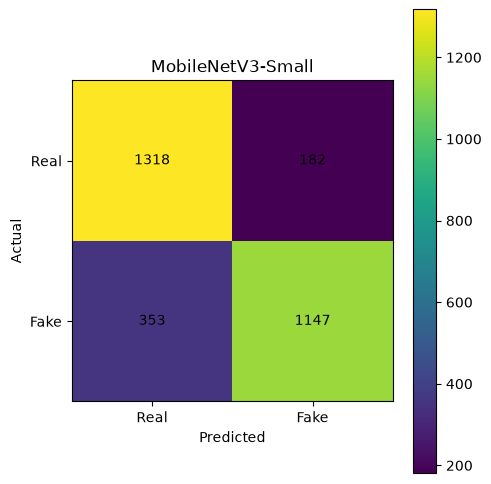

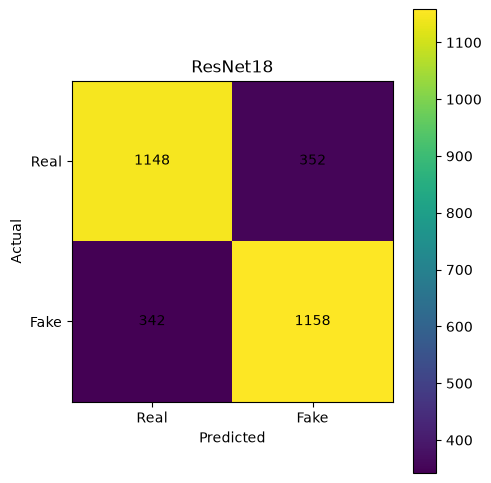

In [20]:
import matplotlib.pyplot as plt

def show_confusion_matrix(
    y_true,
    y_pred,
    title
):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(5,5))

    plt.imshow(cm)

    plt.title(title)

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks(
        [0,1],
        ["Real", "Fake"]
    )

    plt.yticks(
        [0,1],
        ["Real", "Fake"]
    )

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                cm[i,j],
                ha="center",
                va="center"
            )

    plt.colorbar()

    plt.tight_layout()

    plt.show()


show_confusion_matrix(
    y_true_m,
    y_pred_m,
    "MobileNetV3-Small"
)

show_confusion_matrix(
    y_true_r,
    y_pred_r,
    "ResNet18"
)

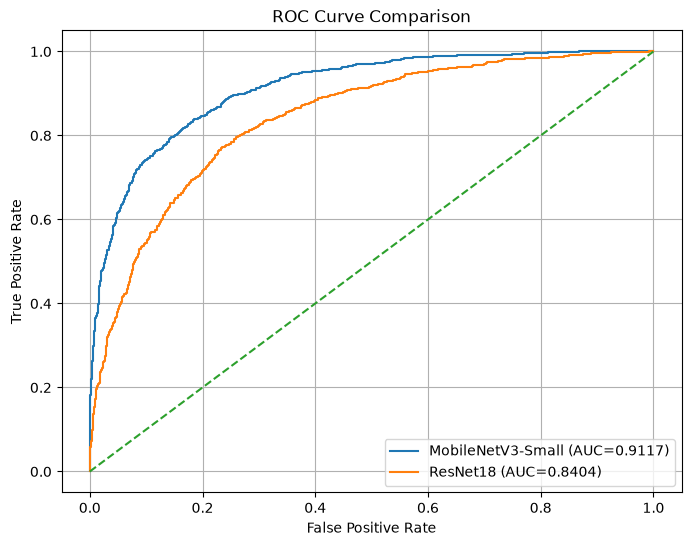

In [21]:
fpr_m, tpr_m, _ = roc_curve(
    y_true_m,
    y_prob_m
)

fpr_r, tpr_r, _ = roc_curve(
    y_true_r,
    y_prob_r
)

plt.figure(figsize=(8,6))

plt.plot(
    fpr_m,
    tpr_m,
    label=f"MobileNetV3-Small "
          f"(AUC={mobilenet_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    fpr_r,
    tpr_r,
    label=f"ResNet18 "
          f"(AUC={resnet_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()

plt.show()

In [22]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
    )


deployment = pd.DataFrame({
    "Parameters": [
        count_parameters(mobilenet),
        count_parameters(resnet18)
    ],
    "Test Inference Time (s)": [
        time_m,
        time_r
    ],
    "Images/sec": [
        len(test_dataset) / time_m,
        len(test_dataset) / time_r
    ]
}, index=[
    "MobileNetV3-Small",
    "ResNet18"
])

print(deployment)

                   Parameters  Test Inference Time (s)  Images/sec
MobileNetV3-Small     1518881                16.844543  178.099220
ResNet18             11177025                66.581617   45.057482


In [27]:
# Unfreeze only the last few feature blocks
for param in mobilenet.features.parameters():
    param.requires_grad = False

for param in mobilenet.features[-3:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in mobilenet.classifier.parameters():
    param.requires_grad = True

print("MobileNet fine-tuning layers enabled.")

MobileNet fine-tuning layers enabled.


In [24]:
mobilenet_ft_history = train_full_model(
    mobilenet,
    "MobileNetV3_Small_FT",
    epochs=5,
    lr=1e-5,
    patience=2
)

Epoch 1/5 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 1/5 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 1/5 (1.10 min)
Train Loss: 0.3535 | Train Acc: 0.8469
Val Loss: 0.3717 | Val Acc: 0.8305
✓ New best model saved


Epoch 2/5 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 2/5 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 2/5 (1.04 min)
Train Loss: 0.3437 | Train Acc: 0.8526
Val Loss: 0.3706 | Val Acc: 0.8371
✓ New best model saved


... (2 outputs left out)


Epoch 3/5 (1.02 min)
Train Loss: 0.3254 | Train Acc: 0.8674
Val Loss: 0.3552 | Val Acc: 0.8362


Epoch 4/5 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 4/5 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 4/5 (1.06 min)
Train Loss: 0.3205 | Train Acc: 0.8649
Val Loss: 0.3624 | Val Acc: 0.8295

Early stopping triggered.

Best validation accuracy: 0.8371


In [28]:
# Freeze everything first
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze final residual block
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Final classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

print("ResNet18 fine-tuning layers enabled.")

ResNet18 fine-tuning layers enabled.


In [29]:
resnet_ft_history = train_full_model(
    resnet18,
    "ResNet18_FT",
    epochs=2,
    lr=1e-5,
    patience=1
)

Epoch 1/2 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 1/2 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 1/2 (3.58 min)
Train Loss: 0.4203 | Train Acc: 0.8089
Val Loss: 0.4190 | Val Acc: 0.8124
✓ New best model saved


Epoch 2/2 Train:   0%|          | 0/186 [00:00<?, ?it/s]

Epoch 2/2 Val:   0%|          | 0/33 [00:00<?, ?it/s]


Epoch 2/2 (3.68 min)
Train Loss: 0.3680 | Train Acc: 0.8375
Val Loss: 0.3957 | Val Acc: 0.8171
✓ New best model saved

Best validation accuracy: 0.8171


In [30]:
y_true_m, y_prob_m, y_pred_m, time_m = get_predictions(
    mobilenet,
    test_loader
)

y_true_r, y_prob_r, y_pred_r, time_r = get_predictions(
    resnet18,
    test_loader
)

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

In [31]:
mobilenet_metrics = get_metrics(
    y_true_m,
    y_prob_m,
    y_pred_m
)

resnet_metrics = get_metrics(
    y_true_r,
    y_prob_r,
    y_pred_r
)

final_results = pd.DataFrame(
    [
        mobilenet_metrics,
        resnet_metrics
    ],
    index=[
        "MobileNetV3-Small",
        "ResNet18"
    ]
)

print(final_results.round(4))

                   Accuracy  Precision  Recall  F1-Score  ROC-AUC
MobileNetV3-Small    0.8313     0.8045  0.8753    0.8384   0.9173
ResNet18             0.8387     0.8307  0.8507    0.8406   0.9198


In [32]:
final_results.to_csv(
    "final_model_results.csv"
)

print("Saved: final_model_results.csv")

Saved: final_model_results.csv


In [33]:
print("MobileNetV3-Small after fine-tuning:")
print(mobilenet_metrics)

print("\nResNet18 after fine-tuning:")
print(resnet_metrics)

MobileNetV3-Small after fine-tuning:
{'Accuracy': 0.8313333333333334, 'Precision': 0.8045343137254902, 'Recall': 0.8753333333333333, 'F1-Score': 0.8384418901660281, 'ROC-AUC': 0.9172986666666667}

ResNet18 after fine-tuning:
{'Accuracy': 0.8386666666666667, 'Precision': 0.8307291666666666, 'Recall': 0.8506666666666667, 'F1-Score': 0.8405797101449275, 'ROC-AUC': 0.9198453333333334}


In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

RESULTS_DIR = "deepfake_results"
os.makedirs(RESULTS_DIR, exist_ok=True)


# Final predictions
y_true_m, y_prob_m, y_pred_m, time_m = get_predictions(
    mobilenet,
    test_loader
)

y_true_r, y_prob_r, y_pred_r, time_r = get_predictions(
    resnet18,
    test_loader
)


# Metrics
mobilenet_metrics = get_metrics(
    y_true_m,
    y_prob_m,
    y_pred_m
)

resnet_metrics = get_metrics(
    y_true_r,
    y_prob_r,
    y_pred_r
)


final_results = pd.DataFrame(
    [mobilenet_metrics, resnet_metrics],
    index=[
        "MobileNetV3-Small",
        "ResNet18"
    ]
)

print(final_results.round(4))

final_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "final_model_results.csv"
    )
)

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

Testing:   0%|          | 0/94 [00:00<?, ?it/s]

                   Accuracy  Precision  Recall  F1-Score  ROC-AUC
MobileNetV3-Small    0.8313     0.8045  0.8753    0.8384   0.9173
ResNet18             0.8387     0.8307  0.8507    0.8406   0.9198


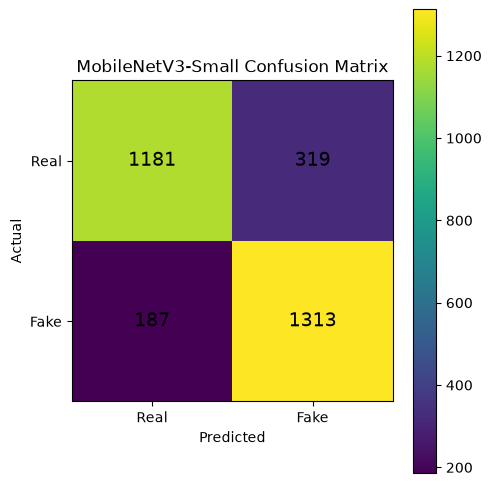

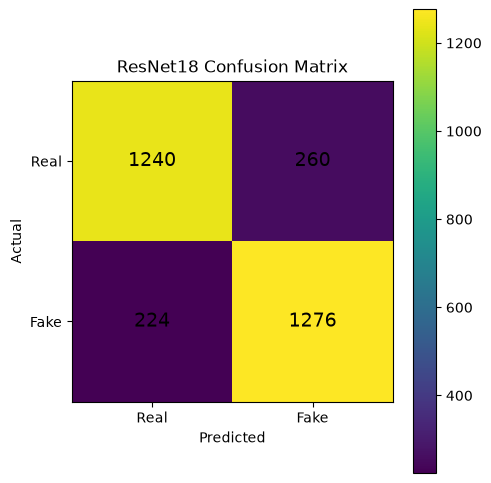

In [35]:
from sklearn.metrics import confusion_matrix

def save_confusion_matrix(
    y_true,
    y_pred,
    model_name
):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(5,5))

    plt.imshow(cm)

    plt.title(
        f"{model_name} Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks(
        [0,1],
        ["Real", "Fake"]
    )

    plt.yticks(
        [0,1],
        ["Real", "Fake"]
    )

    for i in range(2):
        for j in range(2):

            plt.text(
                j,
                i,
                cm[i,j],
                ha="center",
                va="center",
                fontsize=14
            )

    plt.colorbar()

    plt.tight_layout()

    filename = os.path.join(
        RESULTS_DIR,
        f"{model_name}_confusion_matrix.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


save_confusion_matrix(
    y_true_m,
    y_pred_m,
    "MobileNetV3-Small"
)

save_confusion_matrix(
    y_true_r,
    y_pred_r,
    "ResNet18"
)

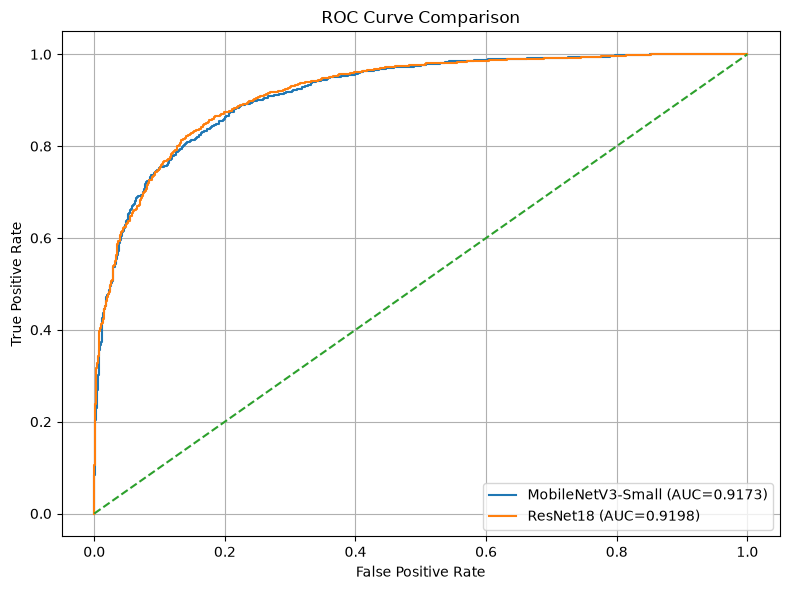

In [36]:
from sklearn.metrics import roc_curve

fpr_m, tpr_m, _ = roc_curve(
    y_true_m,
    y_prob_m
)

fpr_r, tpr_r, _ = roc_curve(
    y_true_r,
    y_prob_r
)

plt.figure(figsize=(8,6))

plt.plot(
    fpr_m,
    tpr_m,
    label=(
        f"MobileNetV3-Small "
        f"(AUC={mobilenet_metrics['ROC-AUC']:.4f})"
    )
)

plt.plot(
    fpr_r,
    tpr_r,
    label=(
        f"ResNet18 "
        f"(AUC={resnet_metrics['ROC-AUC']:.4f})"
    )
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "ROC_comparison.png"
    ),
    dpi=300
)

plt.show()

In [37]:
def model_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
    )


deployment_results = pd.DataFrame({

    "Parameters": [
        model_parameters(mobilenet),
        model_parameters(resnet18)
    ],

    "Inference Time (seconds)": [
        time_m,
        time_r
    ],

    "Images per Second": [
        len(test_dataset) / time_m,
        len(test_dataset) / time_r
    ]

}, index=[
    "MobileNetV3-Small",
    "ResNet18"
])

print(
    deployment_results.round(2)
)

deployment_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "deployment_results.csv"
    )
)

                   Parameters  Inference Time (seconds)  Images per Second
MobileNetV3-Small     1518881                     16.28             184.23
ResNet18             11177025                     72.59              41.33


In [32]:
Device: cpu
Dataset: /home/student/Downloads/rvf10k
Class mapping: {'fake': 0, 'real': 1}
Training-source images: 7000
Training images: 5950
Validation images: 1050
Trainable parameters: 1,236,513 / 1,518,881
Loaded existing fine-tuned checkpoint.

Epoch 1/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 1/10 | Train loss 0.3257, acc 0.8629 | Val loss 0.3249, acc 0.8600 | Time 2.2 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 2/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 2/10 | Train loss 0.3219, acc 0.8588 | Val loss 0.3130, acc 0.8648 | Time 1.0 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 3/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 3/10 | Train loss 0.3094, acc 0.8728 | Val loss 0.3056, acc 0.8743 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 4/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 4/10 | Train loss 0.3106, acc 0.8696 | Val loss 0.3036, acc 0.8695 | Time 1.1 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 5/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 5/10 | Train loss 0.3058, acc 0.8676 | Val loss 0.2985, acc 0.8819 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 6/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 6/10 | Train loss 0.3004, acc 0.8745 | Val loss 0.2948, acc 0.8810 | Time 1.0 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 7/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 7/10 | Train loss 0.2940, acc 0.8773 | Val loss 0.2876, acc 0.8790 | Time 1.1 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 8/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 8/10 | Train loss 0.2932, acc 0.8741 | Val loss 0.2863, acc 0.8857 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 9/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 9/10 | Train loss 0.2828, acc 0.8803 | Val loss 0.2882, acc 0.8810 | Time 1.1 min
No validation-loss improvement.

Epoch 10/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 10/10 | Train loss 0.2725, acc 0.8909 | Val loss 0.2786, acc 0.8886 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Training complete.
Best validation loss: 0.27858
Checkpoint: /home/student/deepfake_env/MobileNetV3_Small_extended_best.pth
History: /home/student/deepfake_env/MobileNetV3_Small_extended_history.csv
import time
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

In [33]:
import os
from torchvision import datasets, transforms

DATASET_PATH = "/home/student/Downloads/rvf10k"

test_base = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "valid")
)

print("Test images:", len(test_base))
print("Class mapping:", test_base.class_to_idx)

Test images: 3000
Class mapping: {'fake': 0, 'real': 1}


In [34]:
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import numpy as np

def get_metrics(y_true, y_prob, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

print("get_metrics() restored successfully!")

get_metrics() restored successfully!


In [37]:
jpeg_levels = [90, 70, 50, 30]

for quality in jpeg_levels:
    for model, model_name in [
        (mobilenet, "MobileNetV3-Small"),
        (resnet18, "ResNet18")
    ]:
        result = evaluate_corruption(
            model,
            apply_jpeg,
            quality,
            model_name,
            "JPEG"
        )

        robustness_results.append(result)

        # Save after every completed condition
        pd.DataFrame(robustness_results).to_csv(
            "/home/student/deepfake_env/deepfake_results/robustness_results.csv",
            index=False
        )

print("JPEG evaluation completed and saved!")

MobileNetV3-Small | JPEG=90:   0%|          | 0/3000 [00:00<?, ?it/s]

ResNet18 | JPEG=90:   0%|          | 0/3000 [00:00<?, ?it/s]

MobileNetV3-Small | JPEG=70:   0%|          | 0/3000 [00:00<?, ?it/s]

ResNet18 | JPEG=70:   0%|          | 0/3000 [00:00<?, ?it/s]

MobileNetV3-Small | JPEG=50:   0%|          | 0/3000 [00:00<?, ?it/s]

ResNet18 | JPEG=50:   0%|          | 0/3000 [00:00<?, ?it/s]

MobileNetV3-Small | JPEG=30:   0%|          | 0/3000 [00:00<?, ?it/s]

ResNet18 | JPEG=30:   0%|          | 0/3000 [00:00<?, ?it/s]

JPEG evaluation completed and saved!


In [38]:
from PIL import Image, ImageFilter, ImageEnhance
from io import BytesIO
import numpy as np
import torch

def apply_jpeg(image, quality):
    # Make sure input is PIL
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)

    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=int(quality))
    buffer.seek(0)

    return Image.open(buffer).convert("RGB")


def apply_blur(image, radius):
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)

    return image.filter(ImageFilter.GaussianBlur(radius=float(radius)))


def apply_noise(image, sigma):
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)

    arr = np.array(image).astype(np.float32)

    noise = np.random.normal(
        0,
        float(sigma),
        arr.shape
    )

    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)

    return Image.fromarray(arr)


def apply_brightness(image, factor):
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)

    return ImageEnhance.Brightness(image).enhance(float(factor))


def apply_resolution(image, scale):
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)

    w, h = image.size

    new_size = (
        max(1, int(w * scale)),
        max(1, int(h * scale))
    )

    small = image.resize(new_size, Image.Resampling.BILINEAR)

    return small.resize(
        (w, h),
        Image.Resampling.BILINEAR
    )

In [39]:
def evaluate_corruption(
    model,
    corruption_function,
    severity,
    model_name,
    corruption_name
):
    
    model.eval()

    y_true = []
    y_prob = []

    start = time.perf_counter()

    for idx in tqdm(
        range(len(test_base)),
        desc=f"{model_name} | {corruption_name}={severity}"
    ):
        
        # Get RAW PIL image
        image, original_label = test_base[idx]

        # Convert ImageFolder label:
        # fake = 0, real = 1
        # Our convention:
        # real = 0, fake = 1
        label = 1 - original_label

        # Apply corruption to PIL image
        corrupted_image = corruption_function(
            image,
            severity
        )

        # Apply normal evaluation preprocessing
        image_tensor = test_transform(
            corrupted_image
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(image_tensor)
            probability = torch.sigmoid(output).item()

        y_true.append(label)
        y_prob.append(probability)

    elapsed = time.perf_counter() - start

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = get_metrics(
        y_true,
        y_prob,
        y_pred
    )

    metrics["Model"] = model_name
    metrics["Corruption"] = corruption_name
    metrics["Severity"] = severity
    metrics["Inference Time (s)"] = elapsed

    return metrics

In [2]:
import pandas as pd
import os

ROBUSTNESS_CSV = (
    "/home/student/deepfake_env/deepfake_results/"
    "robustness_results.csv"
)

if os.path.exists(ROBUSTNESS_CSV):
    robustness_df = pd.read_csv(ROBUSTNESS_CSV)

    print("Saved robustness results:", len(robustness_df))

    if len(robustness_df) > 0:
        columns_to_show = [
            col for col in [
                "Model",
                "Corruption",
                "Severity",
                "Accuracy",
                "Precision",
                "Recall",
                "F1-Score",
                "ROC-AUC",
                "Num Images"
            ]
            if col in robustness_df.columns
        ]

        display(robustness_df[columns_to_show])
    else:
        print("No completed robustness conditions saved yet.")
else:
    print("No robustness CSV found yet.")
    print("Clean model results are saved separately.")

Saved robustness results: 8


,Model,Corruption,Severity,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MobileNetV3-Small,JPEG,90,0.822000,0.787500,0.882000,0.832075,0.910443
1,ResNet18,JPEG,90,0.832667,0.824447,0.845333,0.834760,0.916455
2,MobileNetV3-Small,JPEG,70,0.802333,0.762290,0.878667,0.816352,0.886103
3,ResNet18,JPEG,70,0.794667,0.895349,0.667333,0.764706,0.908499
4,MobileNetV3-Small,JPEG,50,0.785333,0.753254,0.848667,0.798119,0.873233
5,ResNet18,JPEG,50,0.758000,0.933857,0.555333,0.696488,0.899251
6,MobileNetV3-Small,JPEG,30,0.770333,0.752648,0.805333,0.778100,0.851182
7,ResNet18,JPEG,30,0.663667,0.953789,0.344000,0.505634,0.879092


In [ ]:
consistency_results = pd.DataFrame([
    {
        "Model": "MobileNetV3-Small",
        "Corruption": "JPEG",
        "Severity": 50,
        **mobile_jpeg_consistency
    },
    {
        "Model": "ResNet18",
        "Corruption": "JPEG",
        "Severity": 50,
        **resnet_jpeg_consistency
    }
])

print(consistency_results)

consistency_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "explanation_consistency.csv"
    ),
    index=False
)

In [ ]:
torch.save(
    mobilenet.state_dict(),
    os.path.join(
        RESULTS_DIR,
        "MobileNetV3_Small_FINAL.pth"
    )
)

torch.save(
    resnet18.state_dict(),
    os.path.join(
        RESULTS_DIR,
        "ResNet18_FINAL.pth"
    )
)

print("Final models saved.")

In [ ]:
print("\n===== FINAL RESULTS FILES =====\n")

for file in sorted(
    os.listdir(RESULTS_DIR)
):

    print(file)

In [8]:
import os

print("Current directory:", os.getcwd())

for root, dirs, files in os.walk(os.getcwd()):
    for f in files:
        if f.endswith(".pth"):
            print(os.path.join(root, f))

Current directory: /home/student/deepfake_env
/home/student/deepfake_env/ResNet18_FT_best.pth
/home/student/deepfake_env/ResNet18_best.pth
/home/student/deepfake_env/MobileNetV3_Small_best.pth
/home/student/deepfake_env/MobileNetV3_Small_FT_best.pth
/home/student/deepfake_env/lib/python3.11/site-packages/distutils-precedence.pth


In [9]:

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = "/home/student/deepfake_env"

# Restore MobileNetV3-Small architecture
mobilenet = models.mobilenet_v3_small(weights=None)
num_features = mobilenet.classifier[-1].in_features
mobilenet.classifier[-1] = nn.Linear(num_features, 1)

mobilenet.load_state_dict(
    torch.load(
        os.path.join(CHECKPOINT_DIR, "MobileNetV3_Small_FT_best.pth"),
        map_location=device,
        weights_only=True
    )
)
mobilenet = mobilenet.to(device).eval()

# Restore ResNet18 architecture
resnet18 = models.resnet18(weights=None)
num_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_features, 1)

resnet18.load_state_dict(
    torch.load(
        os.path.join(CHECKPOINT_DIR, "ResNet18_FT_best.pth"),
        map_location=device,
        weights_only=True
    )
)
resnet18 = resnet18.to(device).eval()

print("MobileNetV3-Small restored successfully")
print("ResNet18 restored successfully")
print("Device:", device)


MobileNetV3-Small restored successfully
ResNet18 restored successfully
Device: cpu


In [14]:
import pandas as pd

results_path = (
    "/home/student/deepfake_env/deepfake_results/"
    "final_model_results.csv"
)

df = pd.read_csv(results_path)
display(df)

,Unnamed: 0,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MobileNetV3-Small,0.831333,0.804534,0.875333,0.838442,0.917299
1,ResNet18,0.838667,0.830729,0.850667,0.840580,0.919845


In [15]:
deployment_path = (
    "/home/student/deepfake_env/deepfake_results/"
    "deployment_results.csv"
)

display(pd.read_csv(deployment_path))

,Unnamed: 0,Parameters,Inference Time (seconds),Images per Second
0,MobileNetV3-Small,1518881,16.284200,184.227661
1,ResNet18,11177025,72.593266,41.326147


In [16]:
import os
import shutil

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
BACKUP_DIR = os.path.join(RESULTS_DIR, "backup_clean_results")

os.makedirs(BACKUP_DIR, exist_ok=True)

for filename in [
    "final_model_results.csv",
    "deployment_results.csv",
    "MobileNetV3-Small_confusion_matrix.png",
    "ResNet18_confusion_matrix.png",
    "ROC_comparison.png"
]:
    src = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(src):
        shutil.copy2(src, BACKUP_DIR)
        print("Backed up:", filename)

print("Clean evaluation backup complete.")

Backed up: final_model_results.csv
Backed up: deployment_results.csv
Backed up: MobileNetV3-Small_confusion_matrix.png
Backed up: ResNet18_confusion_matrix.png
Backed up: ROC_comparison.png
Clean evaluation backup complete.


In [4]:
import os
import time
import numpy as np
import pandas as pd
import torch

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

ROBUSTNESS_CSV = os.path.join(
    RESULTS_DIR, "robustness_results.csv"
)

# Restore the in-memory list from disk if possible
if os.path.exists(ROBUSTNESS_CSV):
    robustness_results = pd.read_csv(
        ROBUSTNESS_CSV
    ).to_dict("records")
    print("Loaded saved rows:", len(robustness_results))
else:
    robustness_results = []
    print("No saved robustness CSV; starting an empty results list.")

print("Models available:", "mobilenet" in globals(),
      "resnet18" in globals())
print("Test dataset available:", "test_base" in globals())

Loaded saved rows: 8
Models available: False False
Test dataset available: False


In [5]:
import os
import torch
import torch.nn as nn
from torchvision import models, datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = "/home/student/deepfake_env"
DATASET_PATH = "/home/student/Downloads/rvf10k"

# Restore MobileNetV3-Small
mobilenet = models.mobilenet_v3_small(weights=None)
mobilenet.classifier[-1] = nn.Linear(
    mobilenet.classifier[-1].in_features, 1
)
mobilenet.load_state_dict(torch.load(
    os.path.join(CHECKPOINT_DIR, "MobileNetV3_Small_FT_best.pth"),
    map_location=device,
    weights_only=True
))
mobilenet = mobilenet.to(device).eval()

# Restore ResNet18
resnet18 = models.resnet18(weights=None)
resnet18.fc = nn.Linear(resnet18.fc.in_features, 1)
resnet18.load_state_dict(torch.load(
    os.path.join(CHECKPOINT_DIR, "ResNet18_FT_best.pth"),
    map_location=device,
    weights_only=True
))
resnet18 = resnet18.to(device).eval()

# Restore test dataset
test_base = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "valid")
)

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

print("Models restored:", True)
print("Test images:", len(test_base))
print("Class mapping:", test_base.class_to_idx)

Models restored: True
Test images: 3000
Class mapping: {'fake': 0, 'real': 1}


In [6]:
import pandas as pd
import os

ROBUSTNESS_CSV = (
    "/home/student/deepfake_env/deepfake_results/"
    "robustness_results.csv"
)

robustness_df = pd.read_csv(ROBUSTNESS_CSV)

print("Saved conditions:", len(robustness_df))
display(robustness_df)

Saved conditions: 8


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Model,Corruption,Severity,Inference Time (s)
0,0.822000,0.787500,0.882000,0.832075,0.910443,MobileNetV3-Small,JPEG,90,28.094919
1,0.832667,0.824447,0.845333,0.834760,0.916455,ResNet18,JPEG,90,86.519642
2,0.802333,0.762290,0.878667,0.816352,0.886103,MobileNetV3-Small,JPEG,70,29.130378
3,0.794667,0.895349,0.667333,0.764706,0.908499,ResNet18,JPEG,70,85.834316
4,0.785333,0.753254,0.848667,0.798119,0.873233,MobileNetV3-Small,JPEG,50,30.052291
5,0.758000,0.933857,0.555333,0.696488,0.899251,ResNet18,JPEG,50,91.592650
6,0.770333,0.752648,0.805333,0.778100,0.851182,MobileNetV3-Small,JPEG,30,30.988581
7,0.663667,0.953789,0.344000,0.505634,0.879092,ResNet18,JPEG,30,90.024495


In [7]:
import time
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def get_metrics(y_true, y_prob, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

print("Evaluation helpers restored.")

Evaluation helpers restored.


In [8]:
import pandas as pd
import os

ROBUSTNESS_CSV = (
    "/home/student/deepfake_env/deepfake_results/"
    "robustness_results.csv"
)

robustness_df = pd.read_csv(ROBUSTNESS_CSV)

print("Total saved rows:", len(robustness_df))
print("\nSaved conditions:")

display(
    robustness_df[
        ["Model", "Corruption", "Severity", "Accuracy", "F1-Score"]
    ].sort_values(["Corruption", "Severity", "Model"])
)

Total saved rows: 8

Saved conditions:


,Model,Corruption,Severity,Accuracy,F1-Score
6,MobileNetV3-Small,JPEG,30,0.770333,0.778100
7,ResNet18,JPEG,30,0.663667,0.505634
4,MobileNetV3-Small,JPEG,50,0.785333,0.798119
5,ResNet18,JPEG,50,0.758000,0.696488
2,MobileNetV3-Small,JPEG,70,0.802333,0.816352
3,ResNet18,JPEG,70,0.794667,0.764706
0,MobileNetV3-Small,JPEG,90,0.822000,0.832075
1,ResNet18,JPEG,90,0.832667,0.834760


In [9]:

import os
import time
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from PIL import Image, ImageFilter, ImageEnhance
from io import BytesIO
from torchvision import transforms
from sklearn.model_selection import train_test_split

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
ROBUSTNESS_CSV = os.path.join(RESULTS_DIR, "robustness_results.csv")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load existing JPEG results; don't erase them
robustness_df = pd.read_csv(ROBUSTNESS_CSV)

# Fixed, balanced subset of the test set
all_indices = np.arange(len(test_base))
test_labels = np.array([1 - test_base.targets[i] for i in all_indices])

_, selected_indices = train_test_split(
    all_indices,
    test_size=500,
    random_state=42,
    stratify=test_labels
)
selected_indices = np.sort(selected_indices)

# Corruption functions
def apply_blur(image, radius):
    return image.filter(ImageFilter.GaussianBlur(radius=float(radius)))

def apply_noise(image, sigma):
    arr = np.asarray(image).astype(np.float32)
    rng = np.random.default_rng(42)
    # Use deterministic noise per image/severity in evaluator below
    noise = rng.normal(0, float(sigma), arr.shape)
    return Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))

def apply_brightness(image, factor):
    return ImageEnhance.Brightness(image).enhance(float(factor))

def apply_resolution(image, scale):
    w, h = image.size
    small = image.resize(
        (max(1, int(w * scale)), max(1, int(h * scale))),
        Image.Resampling.BILINEAR
    )
    return small.resize((w, h), Image.Resampling.BILINEAR)

print("Saved existing rows:", len(robustness_df))
print("Pilot images per condition:", len(selected_indices))


Saved existing rows: 8
Pilot images per condition: 500


In [10]:

def evaluate_corruption_batched(
    model, corruption_fn, severity, model_name, corruption_name,
    indices, batch_size=32
):
    model.eval()
    labels_all, probs_all = [], []
    batch_x, batch_y = [], []
    start = time.perf_counter()

    def predict_batch():
        if not batch_x:
            return
        x = torch.stack(batch_x).to(device)
        with torch.inference_mode():
            probs = torch.sigmoid(model(x)).cpu().numpy().ravel()
        probs_all.extend(probs.tolist())
        labels_all.extend(batch_y)
        batch_x.clear()
        batch_y.clear()

    for idx in tqdm(indices, desc=f"{model_name} {corruption_name}={severity}"):
        image, original_label = test_base[idx]
        label = 1 - original_label  # fake=1, real=0

        # Deterministic noise across reruns for this image/severity
        if corruption_name == "Gaussian Noise":
            arr = np.asarray(image).astype(np.float32)
            rng = np.random.default_rng(42 + int(idx) + int(severity) * 100000)
            arr = np.clip(
                arr + rng.normal(0, float(severity), arr.shape),
                0, 255
            ).astype(np.uint8)
            corrupted = Image.fromarray(arr)
        else:
            corrupted = corruption_fn(image, severity)

        batch_x.append(test_transform(corrupted))
        batch_y.append(label)

        if len(batch_x) >= batch_size:
            predict_batch()

    predict_batch()

    y_true = np.asarray(labels_all)
    y_prob = np.asarray(probs_all)
    y_pred = (y_prob >= 0.5).astype(int)

    result = get_metrics(y_true, y_prob, y_pred)
    result.update({
        "Model": model_name,
        "Corruption": corruption_name,
        "Severity": severity,
        "Inference Time (s)": time.perf_counter() - start,
        "Num Images": len(y_true),
        "Sample Seed": 42
    })
    return result


In [11]:

experiments = [
    ("Gaussian Blur", apply_blur, [1, 2, 3, 5]),
    ("Gaussian Noise", apply_noise, [5, 15, 25, 40]),
    ("Brightness", apply_brightness, [0.6, 0.8, 1.2, 1.4]),
    ("Resolution", apply_resolution, [0.75, 0.50, 0.25])
]

models_to_test = [
    (mobilenet, "MobileNetV3-Small"),
    (resnet18, "ResNet18")
]

for corruption_name, corruption_fn, levels in experiments:
    for severity in levels:
        for model, model_name in models_to_test:

            # Reload CSV each time so completed work is preserved
            robustness_df = pd.read_csv(ROBUSTNESS_CSV)

            already_done = (
                (robustness_df["Model"] == model_name)
                & (robustness_df["Corruption"] == corruption_name)
                & (robustness_df["Severity"].astype(str) == str(severity))
                & (robustness_df.get(
                    "Num Images", pd.Series(index=robustness_df.index, dtype=float)
                ).fillna(0).astype(int) == len(selected_indices))
            ).any()

            if already_done:
                print("Skipping saved condition:", model_name, corruption_name, severity)
                continue

            result = evaluate_corruption_batched(
                model, corruption_fn, severity,
                model_name, corruption_name,
                selected_indices, batch_size=32
            )

            robustness_df = pd.concat(
                [robustness_df, pd.DataFrame([result])],
                ignore_index=True
            )
            robustness_df.to_csv(ROBUSTNESS_CSV, index=False)
            print("Saved:", model_name, corruption_name, severity)


MobileNetV3-Small Gaussian Blur=1:   0%|          | 0/500 [00:00<?, ?it/s]

Saved: MobileNetV3-Small Gaussian Blur 1


ResNet18 Gaussian Blur=1:   0%|          | 0/500 [00:00<?, ?it/s]

Saved: ResNet18 Gaussian Blur 1


MobileNetV3-Small Gaussian Blur=2:   0%|          | 0/500 [00:00<?, ?it/s]

Saved: MobileNetV3-Small Gaussian Blur 2


... (50 outputs left out)

MobileNetV3-Small Resolution=0.25:   0%|          | 0/500 [00:00<?, ?it/s]

Saved: MobileNetV3-Small Resolution 0.25


ResNet18 Resolution=0.25:   0%|          | 0/500 [00:00<?, ?it/s]

Saved: ResNet18 Resolution 0.25


In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
ROBUSTNESS_CSV = os.path.join(
    RESULTS_DIR, "robustness_results.csv"
)

robustness_df = pd.read_csv(ROBUSTNESS_CSV)

print("Total saved evaluations:", len(robustness_df))
print("\nEvaluations by corruption:")
print(robustness_df.groupby("Corruption").size())

display(
    robustness_df[
        ["Model", "Corruption", "Severity",
         "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
    ].sort_values(["Corruption", "Severity", "Model"])
)

Total saved evaluations: 38

Evaluations by corruption:
Corruption
Brightness        8
Gaussian Blur     8
Gaussian Noise    8
JPEG              8
Resolution        6
dtype: int64


,Model,Corruption,Severity,Accuracy,Precision,Recall,F1-Score,ROC-AUC
24,MobileNetV3-Small,Brightness,0.60,0.830000,0.828685,0.832000,0.830339,0.914048
25,ResNet18,Brightness,0.60,0.848000,0.845238,0.852000,0.848606,0.928944
26,MobileNetV3-Small,Brightness,0.80,0.858000,0.850980,0.868000,0.859406,0.928304
27,ResNet18,Brightness,0.80,0.848000,0.832061,0.872000,0.851562,0.932064
28,MobileNetV3-Small,Brightness,1.20,0.856000,0.847656,0.868000,0.857708,0.927248
29,ResNet18,Brightness,1.20,0.854000,0.883117,0.816000,0.848233,0.923856
30,MobileNetV3-Small,Brightness,1.40,0.828000,0.833333,0.820000,0.826613,0.909008
31,ResNet18,Brightness,1.40,0.802000,0.883249,0.696000,0.778523,0.902384
8,MobileNetV3-Small,Gaussian Blur,1.00,0.822000,0.794872,0.868000,0.829828,0.896512
9,ResNet18,Gaussian Blur,1.00,0.816000,0.887255,0.724000,0.797357,0.905504


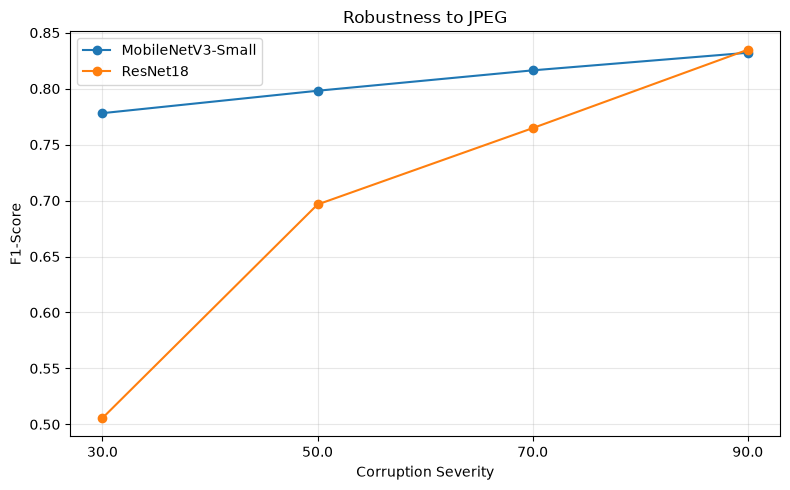

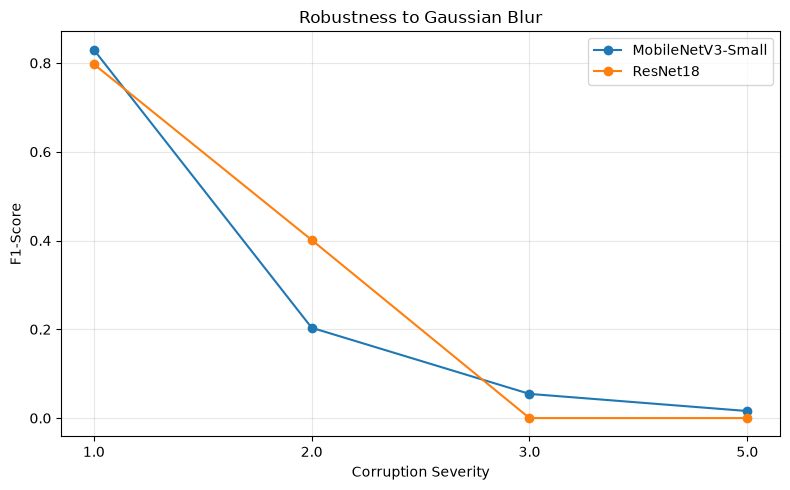

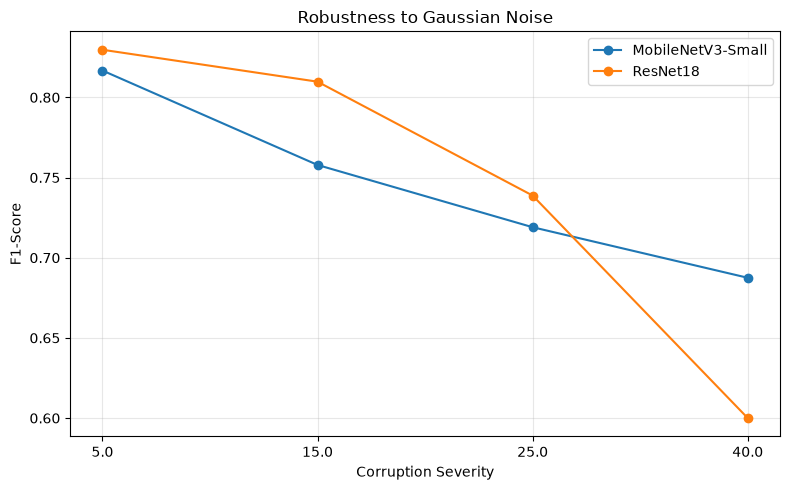

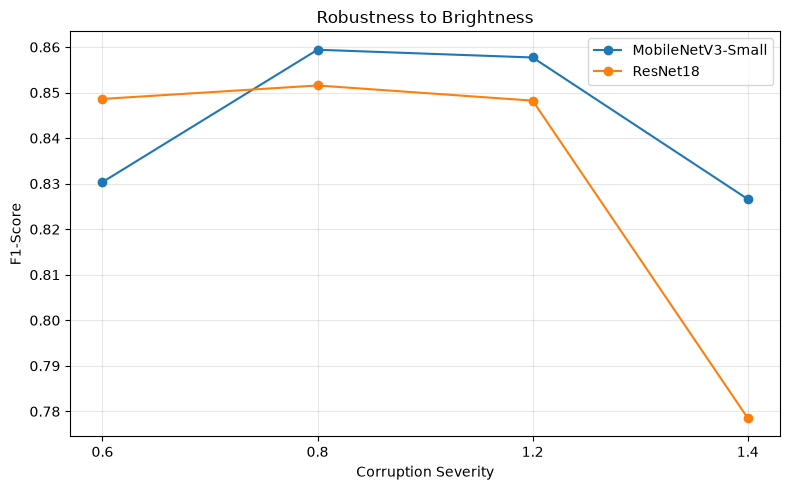

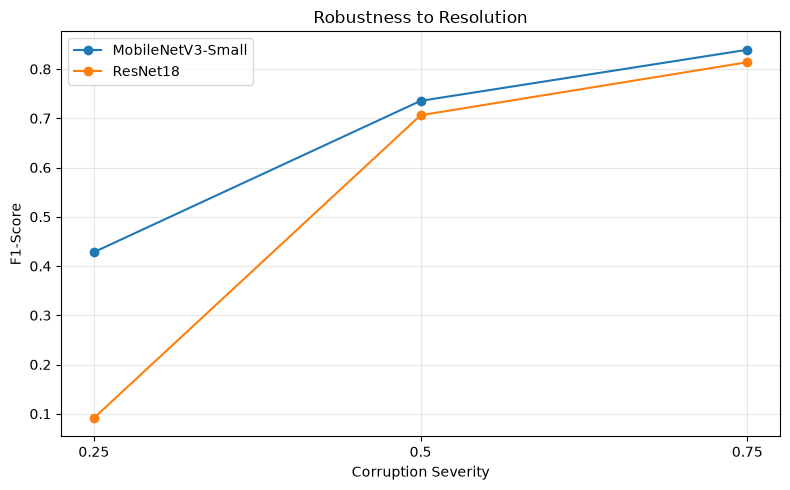

Robustness graphs saved.


In [13]:
for corruption in robustness_df["Corruption"].unique():

    subset = robustness_df[
        robustness_df["Corruption"] == corruption
    ]

    plt.figure(figsize=(8, 5))

    for model_name in ["MobileNetV3-Small", "ResNet18"]:

        model_data = subset[
            subset["Model"] == model_name
        ].sort_values("Severity")

        plt.plot(
            model_data["Severity"].astype(str),
            model_data["F1-Score"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Corruption Severity")
    plt.ylabel("F1-Score")
    plt.title(f"Robustness to {corruption}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = (
        f"robustness_{corruption.lower().replace(' ', '_')}.png"
    )

    plt.savefig(
        os.path.join(RESULTS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Robustness graphs saved.")

Total saved rows: 38

Rows by corruption:
Corruption
Brightness        8
Gaussian Blur     8
Gaussian Noise    8
JPEG              8
Resolution        6
dtype: int64

Rows by model:
Model
MobileNetV3-Small    19
ResNet18             19
dtype: int64


,Model,Corruption,Severity,Accuracy,Precision,Recall,F1-Score,ROC-AUC
24,MobileNetV3-Small,Brightness,0.60,0.830000,0.828685,0.832000,0.830339,0.914048
25,ResNet18,Brightness,0.60,0.848000,0.845238,0.852000,0.848606,0.928944
26,MobileNetV3-Small,Brightness,0.80,0.858000,0.850980,0.868000,0.859406,0.928304
27,ResNet18,Brightness,0.80,0.848000,0.832061,0.872000,0.851562,0.932064
28,MobileNetV3-Small,Brightness,1.20,0.856000,0.847656,0.868000,0.857708,0.927248
29,ResNet18,Brightness,1.20,0.854000,0.883117,0.816000,0.848233,0.923856
30,MobileNetV3-Small,Brightness,1.40,0.828000,0.833333,0.820000,0.826613,0.909008
31,ResNet18,Brightness,1.40,0.802000,0.883249,0.696000,0.778523,0.902384
8,MobileNetV3-Small,Gaussian Blur,1.00,0.822000,0.794872,0.868000,0.829828,0.896512
9,ResNet18,Gaussian Blur,1.00,0.816000,0.887255,0.724000,0.797357,0.905504


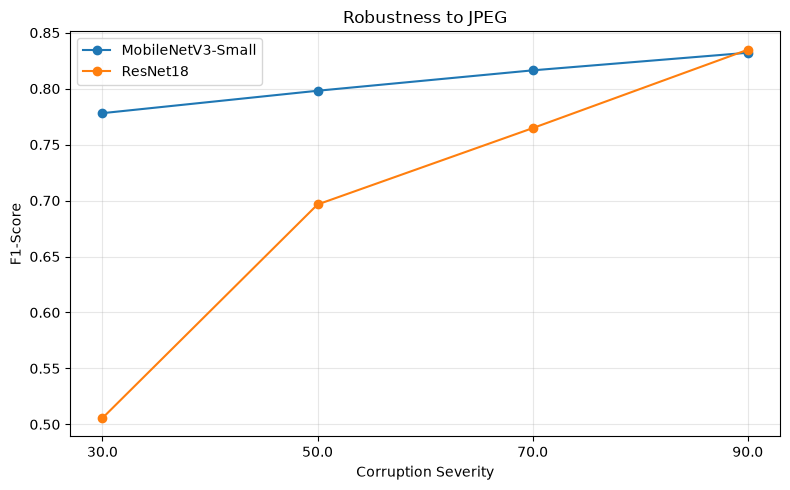

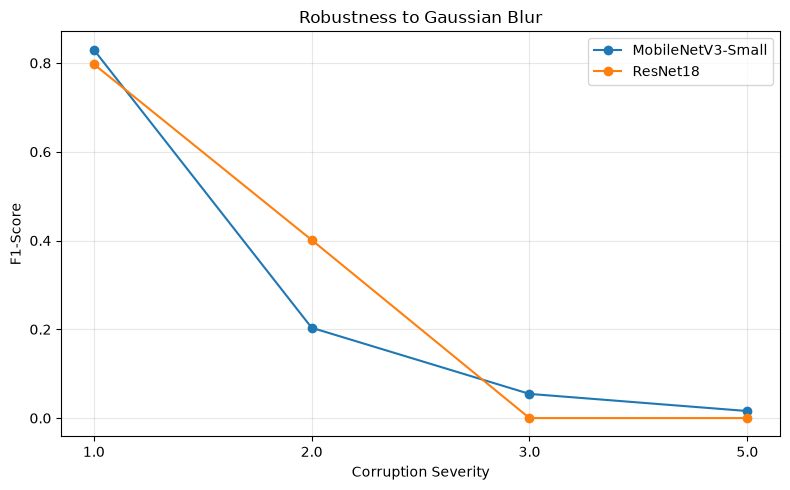

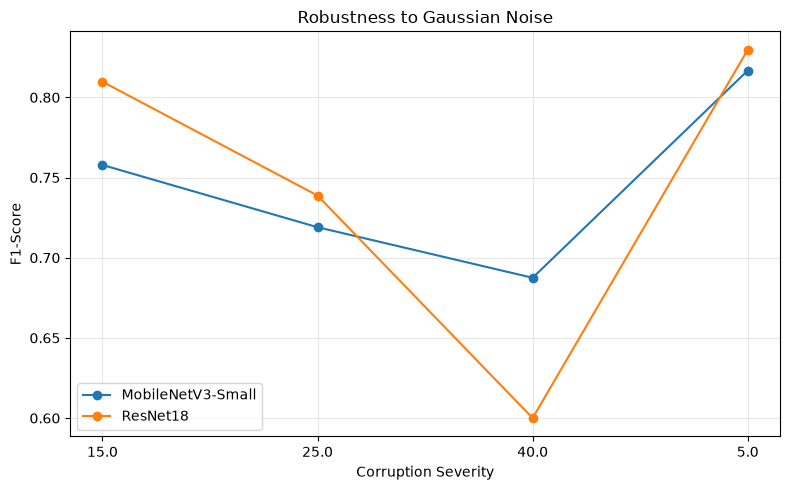

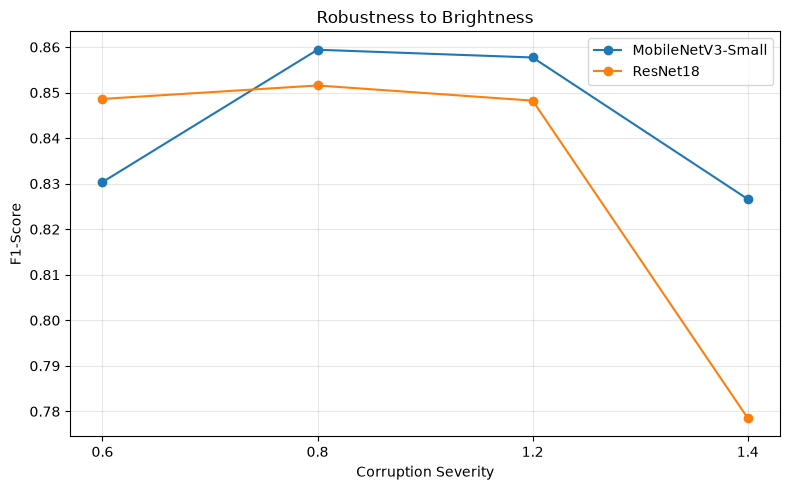

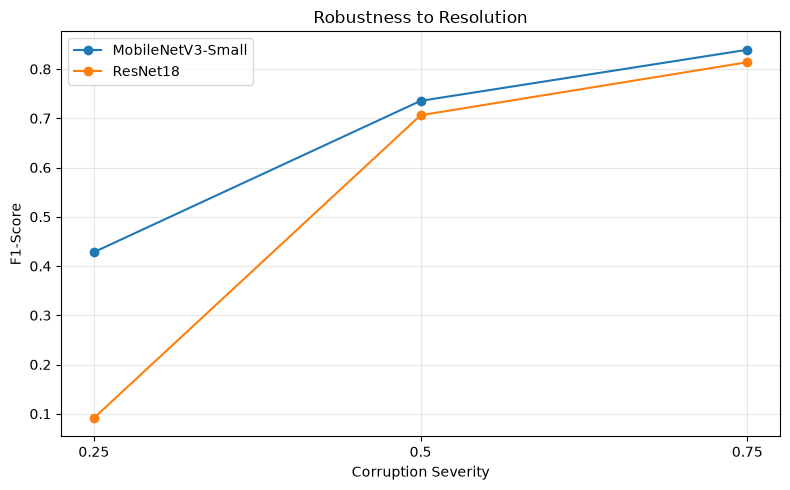

Robustness tables and plots saved.


In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
ROBUSTNESS_CSV = os.path.join(RESULTS_DIR, "robustness_results.csv")
os.makedirs(RESULTS_DIR, exist_ok=True)

robustness_df = pd.read_csv(ROBUSTNESS_CSV)

print("Total saved rows:", len(robustness_df))
print("\nRows by corruption:")
print(robustness_df.groupby("Corruption").size())
print("\nRows by model:")
print(robustness_df.groupby("Model").size())

display(
    robustness_df[
        ["Model", "Corruption", "Severity", "Accuracy",
         "Precision", "Recall", "F1-Score", "ROC-AUC"]
    ].sort_values(["Corruption", "Severity", "Model"])
)

for corruption in robustness_df["Corruption"].unique():
    subset = robustness_df[
        robustness_df["Corruption"] == corruption
    ]

    plt.figure(figsize=(8, 5))

    for model_name in ["MobileNetV3-Small", "ResNet18"]:
        model_data = subset[
            subset["Model"] == model_name
        ].copy()

        model_data = model_data.sort_values(
            "Severity", key=lambda s: s.astype(str)
        )

        plt.plot(
            model_data["Severity"].astype(str),
            model_data["F1-Score"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Corruption Severity")
    plt.ylabel("F1-Score")
    plt.title(f"Robustness to {corruption}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = "robustness_" + "".join(
        c.lower() if c.isalnum() else "_"
        for c in corruption
    ).strip("_") + ".png"

    plt.savefig(
        os.path.join(RESULTS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Robustness tables and plots saved.")

In [18]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

mobilenet.eval()
resnet18.eval()

mobilenet_target_layer = mobilenet.features[-1]
resnet_target_layer = resnet18.layer4[-1]

class BinaryOutputTarget:
    def __init__(self, category):
        self.category = category

    def __call__(self, model_output):
        # Support both [1] and [1, 1] output shapes.
        logit = model_output.reshape(-1)[0]

        # Fake = 1; Real = 0.
        if self.category == 1:
            return logit
        return -logit

print("BinaryOutputTarget fixed.")

def make_gradcam(model, target_layer, pil_image, target_class=None):
    model.eval()

    input_tensor = (
        test_transform(pil_image)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():
        probability = torch.sigmoid(model(input_tensor)).reshape(-1)[0].item()

    predicted_class = int(probability >= 0.5)

    if target_class is None:
        target_class = predicted_class

    with GradCAM(
        model=model,
        target_layers=[target_layer]
    ) as cam:
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[BinaryOutputTarget(target_class)]
        )[0]

    if grayscale_cam is None or grayscale_cam.size == 0:
        raise RuntimeError("Grad-CAM returned an empty heatmap.")

    rgb_image = np.asarray(
        pil_image.convert("RGB").resize((224, 224))
    ).astype(np.float32) / 255.0

    overlay = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    return probability, predicted_class, grayscale_cam, overlay

print("make_gradcam() updated.")

BinaryOutputTarget fixed.
make_gradcam() updated.


P(fake): 0.9744
Prediction: Fake
Heatmap shape: (224, 224)


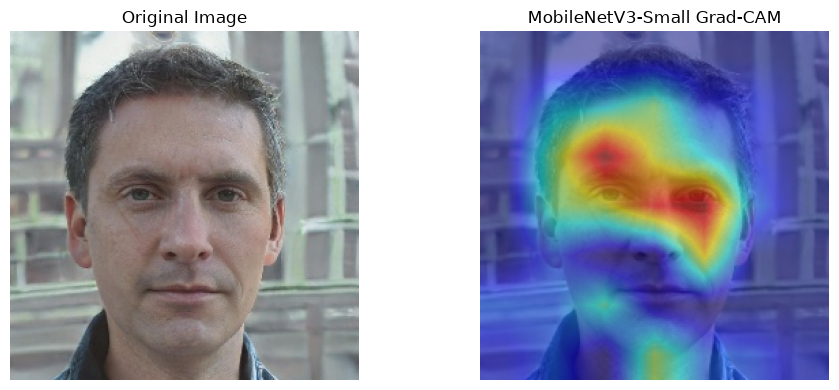

In [19]:
test_image, test_label = test_base[0]

prob, pred, heatmap, overlay = make_gradcam(
    mobilenet,
    mobilenet_target_layer,
    test_image
)

print("P(fake):", round(prob, 4))
print("Prediction:", "Fake" if pred == 1 else "Real")
print("Heatmap shape:", heatmap.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(test_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("MobileNetV3-Small Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

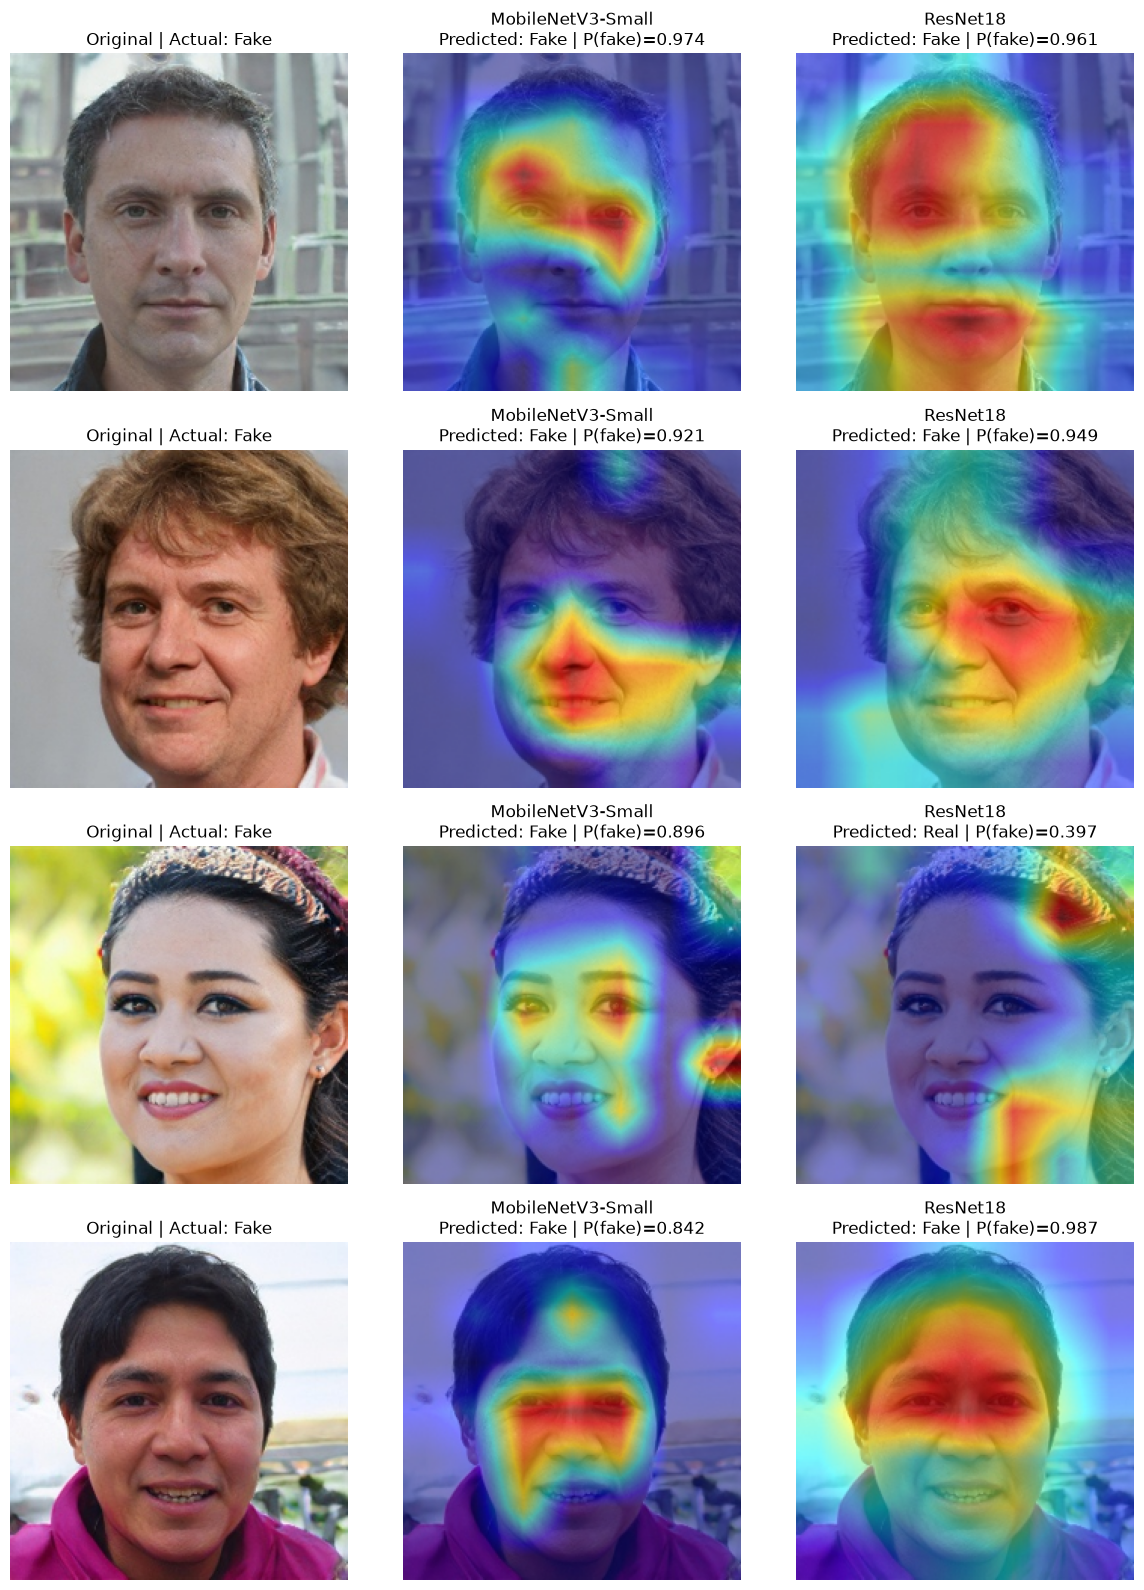

Grad-CAM figure saved: /home/student/deepfake_env/deepfake_results/GradCAM_comparison.png


In [20]:

import random

sample_indices = [0, 100, 500, 1000]

models_for_cam = [
    ("MobileNetV3-Small", mobilenet, mobilenet_target_layer),
    ("ResNet18", resnet18, resnet_target_layer)
]

fig, axes = plt.subplots(
    len(sample_indices), 3,
    figsize=(12, 4 * len(sample_indices))
)

for row, idx in enumerate(sample_indices):
    image, original_label = test_base[idx]
    actual_label = 1 - original_label  # fake=1, real=0

    axes[row, 0].imshow(image.resize((224, 224)))
    axes[row, 0].set_title(
        f"Original | Actual: {'Fake' if actual_label else 'Real'}"
    )
    axes[row, 0].axis("off")

    for col, (name, model, layer) in enumerate(models_for_cam, start=1):
        probability, prediction, heatmap, overlay = make_gradcam(
            model, layer, image
        )

        axes[row, col].imshow(overlay)
        axes[row, col].set_title(
            f"{name}\nPredicted: {'Fake' if prediction else 'Real'} "
            f"| P(fake)={probability:.3f}"
        )
        axes[row, col].axis("off")

plt.tight_layout()

cam_path = os.path.join(RESULTS_DIR, "GradCAM_comparison.png")
plt.savefig(cam_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Grad-CAM figure saved:", cam_path)

In [21]:
from io import BytesIO
from sklearn.metrics.pairwise import cosine_similarity

def apply_jpeg_pil(image, quality):
    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=int(quality))
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")

def heatmap_similarity(a, b):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()

    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)

CONSISTENCY_CSV = os.path.join(
    RESULTS_DIR, "explanation_consistency.csv"
)

consistency_rows = []

# Fixed reproducible sample
rng = np.random.default_rng(42)
consistency_indices = np.sort(
    rng.choice(len(test_base), size=20, replace=False)
)

for model_name, model, target_layer in models_for_cam:
    for idx in consistency_indices:
        image, original_label = test_base[int(idx)]
        compressed = apply_jpeg_pil(image, 50)

        # Use the clean prediction as the target for BOTH heatmaps
        clean_prob, clean_pred, clean_map, _ = make_gradcam(
            model, target_layer, image
        )

        _, _, compressed_map, _ = make_gradcam(
            model, target_layer, compressed,
            target_class=clean_pred
        )

        similarity = heatmap_similarity(clean_map, compressed_map)

        row = {
            "Model": model_name,
            "Image_Index": int(idx),
            "JPEG_Quality": 50,
            "Clean_P_Fake": clean_prob,
            "Clean_Prediction": clean_pred,
            "Heatmap_Cosine_Similarity": similarity
        }
        consistency_rows.append(row)

        # Save after every image so interruption doesn't lose completed work
        current = pd.DataFrame(consistency_rows)
        if os.path.exists(CONSISTENCY_CSV):
            previous = pd.read_csv(CONSISTENCY_CSV)
            current = pd.concat([previous, current], ignore_index=True)
            current = current.drop_duplicates(
                subset=["Model", "Image_Index", "JPEG_Quality"],
                keep="last"
            )

        current.to_csv(CONSISTENCY_CSV, index=False)

    print("Finished consistency analysis:", model_name)

consistency_df = pd.read_csv(CONSISTENCY_CSV)

display(
    consistency_df.groupby("Model")[
        "Heatmap_Cosine_Similarity"
    ].agg(["count", "mean", "std"])
)

print("Consistency results saved:", CONSISTENCY_CSV)

Finished consistency analysis: MobileNetV3-Small
Finished consistency analysis: ResNet18


,count,mean,std
Model,,,
MobileNetV3-Small,20,0.930226,0.058124
ResNet18,20,0.901721,0.149931


Consistency results saved: /home/student/deepfake_env/deepfake_results/explanation_consistency.csv


In [22]:
CLEAN_CSV = os.path.join(RESULTS_DIR, "final_model_results.csv")
DEPLOYMENT_CSV = os.path.join(RESULTS_DIR, "deployment_results.csv")

clean_results = pd.read_csv(CLEAN_CSV)
deployment_results = pd.read_csv(DEPLOYMENT_CSV)

print("CLEAN TEST PERFORMANCE")
display(clean_results)

print("DEPLOYMENT COST")
display(deployment_results)

clean_results.to_csv(
    os.path.join(RESULTS_DIR, "clean_test_metrics_final.csv"),
    index=False
)

deployment_results.to_csv(
    os.path.join(RESULTS_DIR, "deployment_metrics_final.csv"),
    index=False
)

print("Final comparison tables saved.")

CLEAN TEST PERFORMANCE


,Unnamed: 0,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MobileNetV3-Small,0.831333,0.804534,0.875333,0.838442,0.917299
1,ResNet18,0.838667,0.830729,0.850667,0.840580,0.919845


DEPLOYMENT COST


,Unnamed: 0,Parameters,Inference Time (seconds),Images per Second
0,MobileNetV3-Small,1518881,16.284200,184.227661
1,ResNet18,11177025,72.593266,41.326147


Final comparison tables saved.


In [23]:
robustness_df = pd.read_csv(ROBUSTNESS_CSV)

summary = (
    robustness_df.groupby(["Corruption", "Model"])
    .agg(
        Conditions=("Severity", "count"),
        Mean_Accuracy=("Accuracy", "mean"),
        Mean_F1=("F1-Score", "mean"),
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Sample_Sizes=("Num Images", lambda s: ", ".join(
            map(str, sorted(s.dropna().astype(int).unique()))
        ) if "Num Images" in robustness_df.columns else "Check experiment log")
    )
    .reset_index()
)

display(summary.round(4))

summary.to_csv(
    os.path.join(RESULTS_DIR, "robustness_summary.csv"),
    index=False
)

print("Robustness summary saved.")

,Corruption,Model,Conditions,Mean_Accuracy,Mean_F1,Mean_ROC_AUC,Sample_Sizes
0,Brightness,MobileNetV3-Small,4,0.8430,0.8435,0.9197,500
1,Brightness,ResNet18,4,0.8380,0.8317,0.9218,500
2,Gaussian Blur,MobileNetV3-Small,4,0.5965,0.2759,0.7607,500
3,Gaussian Blur,ResNet18,4,0.6080,0.2997,0.7828,500
4,Gaussian Noise,MobileNetV3-Small,4,0.6725,0.7453,0.8142,500
5,Gaussian Noise,ResNet18,4,0.7485,0.7446,0.8233,500
6,JPEG,MobileNetV3-Small,4,0.7950,0.8062,0.8802,
7,JPEG,ResNet18,4,0.7622,0.7004,0.9008,
8,Resolution,MobileNetV3-Small,3,0.7387,0.6676,0.8599,500
9,Resolution,ResNet18,3,0.7040,0.5371,0.8806,500


Robustness summary saved.


In [24]:
print("PROJECT OUTPUTS\n")

for filename in sorted(os.listdir(RESULTS_DIR)):
    filepath = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"{filename:<48} {size_kb:>10.1f} KB")

print("\nVerification complete.")

PROJECT OUTPUTS

GradCAM_comparison.png                               1881.5 KB
MobileNetV3-Small_confusion_matrix.png                 69.2 KB
ROC_comparison.png                                    159.2 KB
ResNet18_confusion_matrix.png                          68.3 KB
clean_test_metrics_final.csv                            0.3 KB
deployment_metrics_final.csv                            0.2 KB
deployment_results.csv                                  0.2 KB
explanation_consistency.csv                             2.5 KB
final_model_results.csv                                 0.3 KB
robustness_brightness.png                             145.1 KB
robustness_gaussian_blur.png                          139.1 KB
robustness_gaussian_noise.png                         163.4 KB
robustness_jpeg.png                                   123.0 KB
robustness_resolution.png                             132.2 KB
robustness_results.csv                                  4.5 KB
robustness_summary.csv                

In [25]:
import os
import pandas as pd

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"

print("===== SAVED PROJECT OUTPUTS =====")

for filename in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(path):
        print(f"{filename}  ({os.path.getsize(path) / 1024:.1f} KB)")

print("\n===== ROBUSTNESS RESULTS =====")

csv_path = os.path.join(RESULTS_DIR, "robustness_results.csv")

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Total rows:", len(df))

    if "Corruption" in df.columns:
        print("\nConditions per corruption:")
        print(df.groupby(["Corruption", "Model"]).size())

    display(df.head(10))
else:
    print("No robustness CSV found.")

===== SAVED PROJECT OUTPUTS =====
GradCAM_comparison.png  (1881.5 KB)
MobileNetV3-Small_confusion_matrix.png  (69.2 KB)
ROC_comparison.png  (159.2 KB)
ResNet18_confusion_matrix.png  (68.3 KB)
clean_test_metrics_final.csv  (0.3 KB)
deployment_metrics_final.csv  (0.2 KB)
deployment_results.csv  (0.2 KB)
explanation_consistency.csv  (2.5 KB)
final_model_results.csv  (0.3 KB)
robustness_brightness.png  (145.1 KB)
robustness_gaussian_blur.png  (139.1 KB)
robustness_gaussian_noise.png  (163.4 KB)
robustness_jpeg.png  (123.0 KB)
robustness_resolution.png  (132.2 KB)
robustness_results.csv  (4.5 KB)
robustness_summary.csv  (0.8 KB)

===== ROBUSTNESS RESULTS =====
Total rows: 38

Conditions per corruption:
Corruption      Model            
Brightness      MobileNetV3-Small    4
                ResNet18             4
Gaussian Blur   MobileNetV3-Small    4
                ResNet18             4
Gaussian Noise  MobileNetV3-Small    4
                ResNet18             4
JPEG            MobileNet

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Model,Corruption,Severity,Inference Time (s),Num Images,Sample Seed
0,0.822000,0.787500,0.882000,0.832075,0.910443,MobileNetV3-Small,JPEG,90.0,28.094919,NaN,NaN
1,0.832667,0.824447,0.845333,0.834760,0.916455,ResNet18,JPEG,90.0,86.519642,NaN,NaN
2,0.802333,0.762290,0.878667,0.816352,0.886103,MobileNetV3-Small,JPEG,70.0,29.130378,NaN,NaN
3,0.794667,0.895349,0.667333,0.764706,0.908499,ResNet18,JPEG,70.0,85.834316,NaN,NaN
4,0.785333,0.753254,0.848667,0.798119,0.873233,MobileNetV3-Small,JPEG,50.0,30.052291,NaN,NaN
5,0.758000,0.933857,0.555333,0.696488,0.899251,ResNet18,JPEG,50.0,91.592650,NaN,NaN
6,0.770333,0.752648,0.805333,0.778100,0.851182,MobileNetV3-Small,JPEG,30.0,30.988581,NaN,NaN
7,0.663667,0.953789,0.344000,0.505634,0.879092,ResNet18,JPEG,30.0,90.024495,NaN,NaN
8,0.822000,0.794872,0.868000,0.829828,0.896512,MobileNetV3-Small,Gaussian Blur,1.0,4.786749,500.0,42.0
9,0.816000,0.887255,0.724000,0.797357,0.905504,ResNet18,Gaussian Blur,1.0,10.936414,500.0,42.0


In [26]:
import os
import pandas as pd

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"

print("===== SAVED PROJECT OUTPUTS =====")

for filename in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(path):
        print(f"{filename}  ({os.path.getsize(path) / 1024:.1f} KB)")

print("\n===== ROBUSTNESS RESULTS =====")

csv_path = os.path.join(RESULTS_DIR, "robustness_results.csv")

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Total rows:", len(df))

    if "Corruption" in df.columns:
        print("\nConditions per corruption:")
        print(df.groupby(["Corruption", "Model"]).size())

    display(df.head(10))
else:
    print("No robustness CSV found.")

===== SAVED PROJECT OUTPUTS =====
GradCAM_comparison.png  (1881.5 KB)
MobileNetV3-Small_confusion_matrix.png  (69.2 KB)
ROC_comparison.png  (159.2 KB)
ResNet18_confusion_matrix.png  (68.3 KB)
clean_test_metrics_final.csv  (0.3 KB)
deployment_metrics_final.csv  (0.2 KB)
deployment_results.csv  (0.2 KB)
explanation_consistency.csv  (2.5 KB)
final_model_results.csv  (0.3 KB)
robustness_brightness.png  (145.1 KB)
robustness_gaussian_blur.png  (139.1 KB)
robustness_gaussian_noise.png  (163.4 KB)
robustness_jpeg.png  (123.0 KB)
robustness_resolution.png  (132.2 KB)
robustness_results.csv  (4.5 KB)
robustness_summary.csv  (0.8 KB)

===== ROBUSTNESS RESULTS =====
Total rows: 38

Conditions per corruption:
Corruption      Model            
Brightness      MobileNetV3-Small    4
                ResNet18             4
Gaussian Blur   MobileNetV3-Small    4
                ResNet18             4
Gaussian Noise  MobileNetV3-Small    4
                ResNet18             4
JPEG            MobileNet

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Model,Corruption,Severity,Inference Time (s),Num Images,Sample Seed
0,0.822000,0.787500,0.882000,0.832075,0.910443,MobileNetV3-Small,JPEG,90.0,28.094919,NaN,NaN
1,0.832667,0.824447,0.845333,0.834760,0.916455,ResNet18,JPEG,90.0,86.519642,NaN,NaN
2,0.802333,0.762290,0.878667,0.816352,0.886103,MobileNetV3-Small,JPEG,70.0,29.130378,NaN,NaN
3,0.794667,0.895349,0.667333,0.764706,0.908499,ResNet18,JPEG,70.0,85.834316,NaN,NaN
4,0.785333,0.753254,0.848667,0.798119,0.873233,MobileNetV3-Small,JPEG,50.0,30.052291,NaN,NaN
5,0.758000,0.933857,0.555333,0.696488,0.899251,ResNet18,JPEG,50.0,91.592650,NaN,NaN
6,0.770333,0.752648,0.805333,0.778100,0.851182,MobileNetV3-Small,JPEG,30.0,30.988581,NaN,NaN
7,0.663667,0.953789,0.344000,0.505634,0.879092,ResNet18,JPEG,30.0,90.024495,NaN,NaN
8,0.822000,0.794872,0.868000,0.829828,0.896512,MobileNetV3-Small,Gaussian Blur,1.0,4.786749,500.0,42.0
9,0.816000,0.887255,0.724000,0.797357,0.905504,ResNet18,Gaussian Blur,1.0,10.936414,500.0,42.0


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Model,Corruption,Severity,Inference Time (s),Num Images,Sample Seed
24,0.830000,0.828685,0.832000,0.830339,0.914048,MobileNetV3-Small,Brightness,0.60,2.732307,500.0,42.0
26,0.858000,0.850980,0.868000,0.859406,0.928304,MobileNetV3-Small,Brightness,0.80,2.735968,500.0,42.0
28,0.856000,0.847656,0.868000,0.857708,0.927248,MobileNetV3-Small,Brightness,1.20,2.753390,500.0,42.0
30,0.828000,0.833333,0.820000,0.826613,0.909008,MobileNetV3-Small,Brightness,1.40,2.760938,500.0,42.0
25,0.848000,0.845238,0.852000,0.848606,0.928944,ResNet18,Brightness,0.60,11.686275,500.0,42.0
27,0.848000,0.832061,0.872000,0.851562,0.932064,ResNet18,Brightness,0.80,10.824365,500.0,42.0
29,0.854000,0.883117,0.816000,0.848233,0.923856,ResNet18,Brightness,1.20,10.830254,500.0,42.0
31,0.802000,0.883249,0.696000,0.778523,0.902384,ResNet18,Brightness,1.40,10.735735,500.0,42.0
8,0.822000,0.794872,0.868000,0.829828,0.896512,MobileNetV3-Small,Gaussian Blur,1.00,4.786749,500.0,42.0
10,0.546000,0.828571,0.116000,0.203509,0.788000,MobileNetV3-Small,Gaussian Blur,2.00,3.477057,500.0,42.0


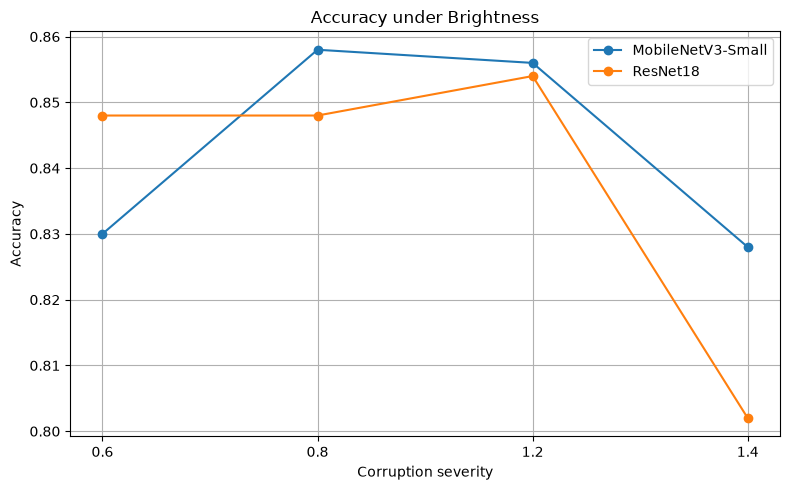

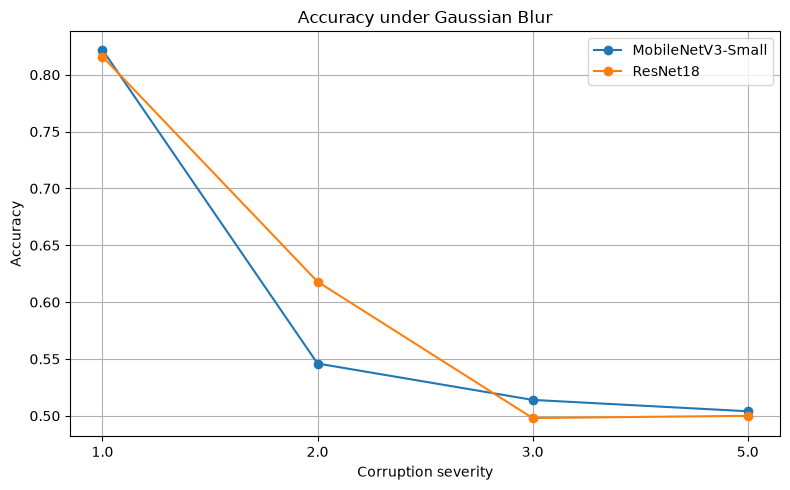

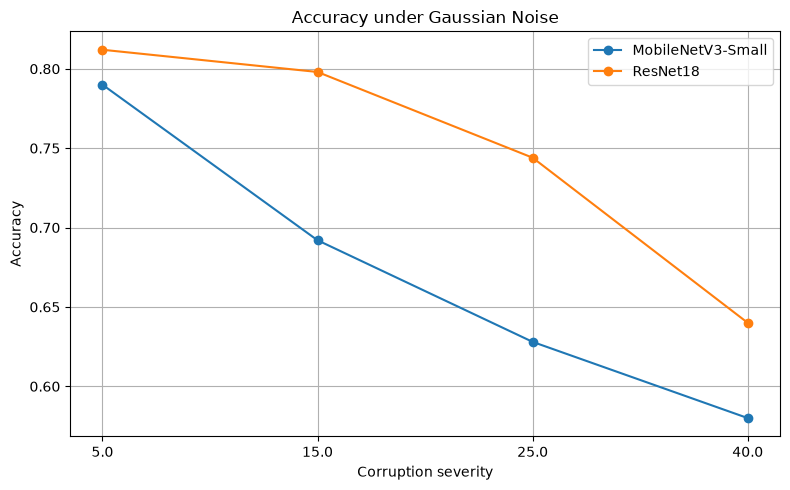

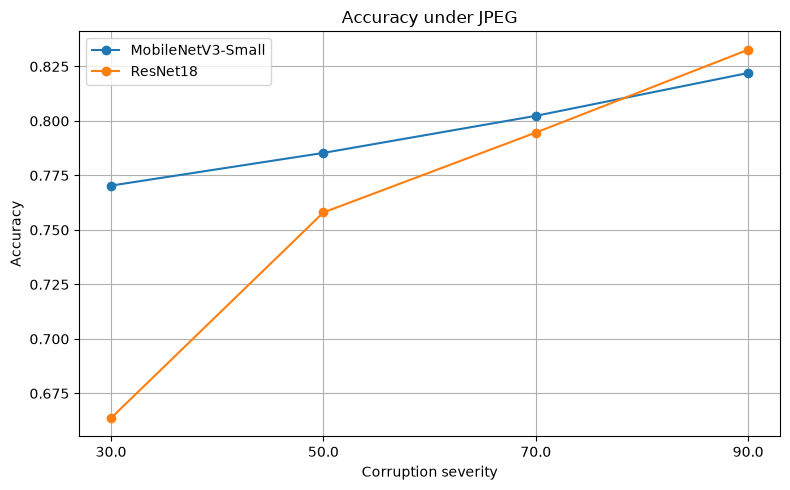

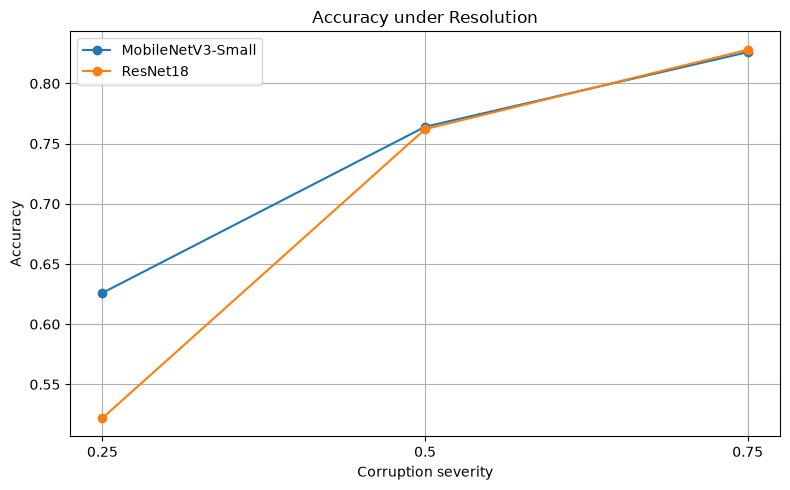

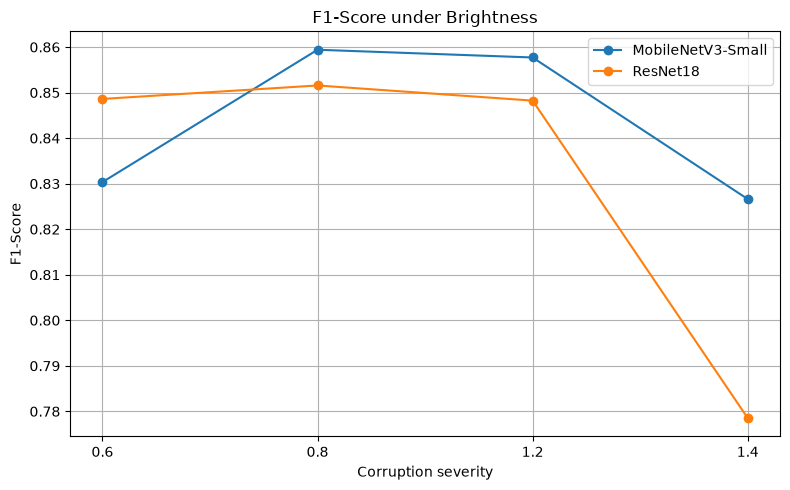

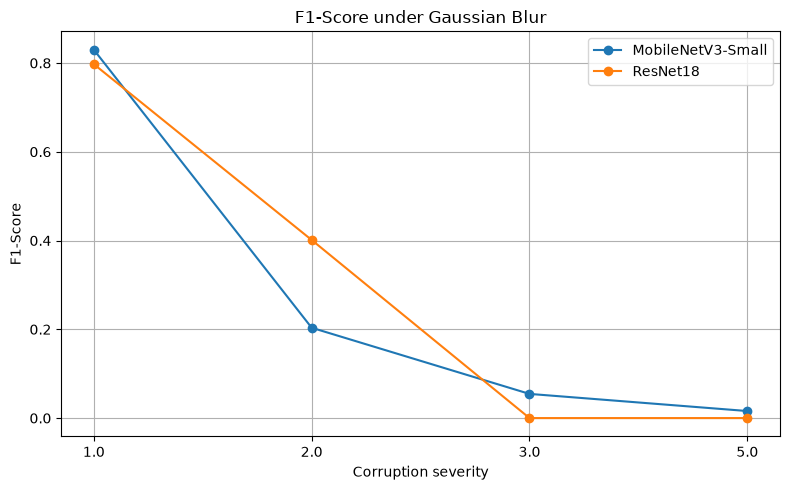

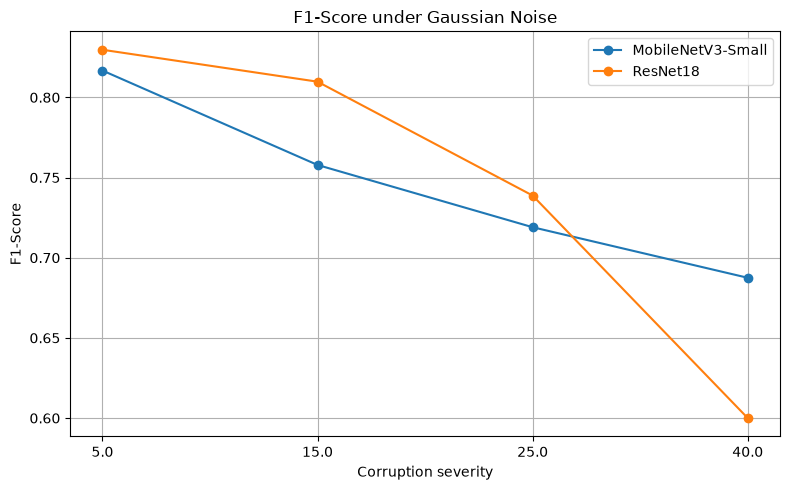

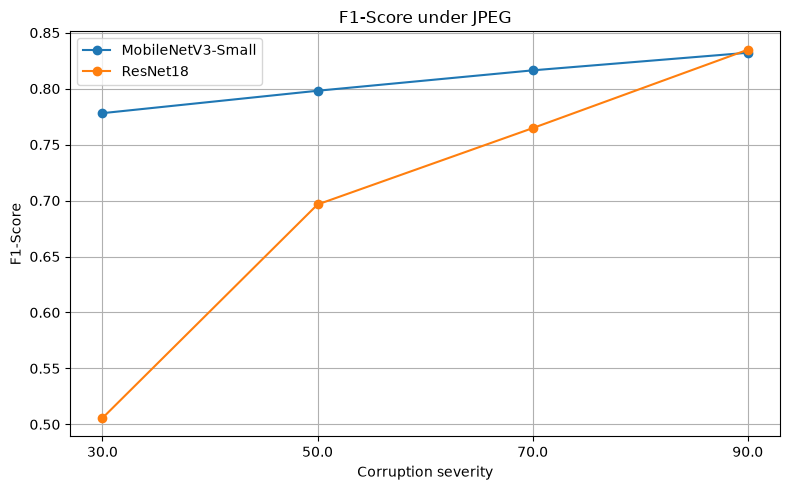

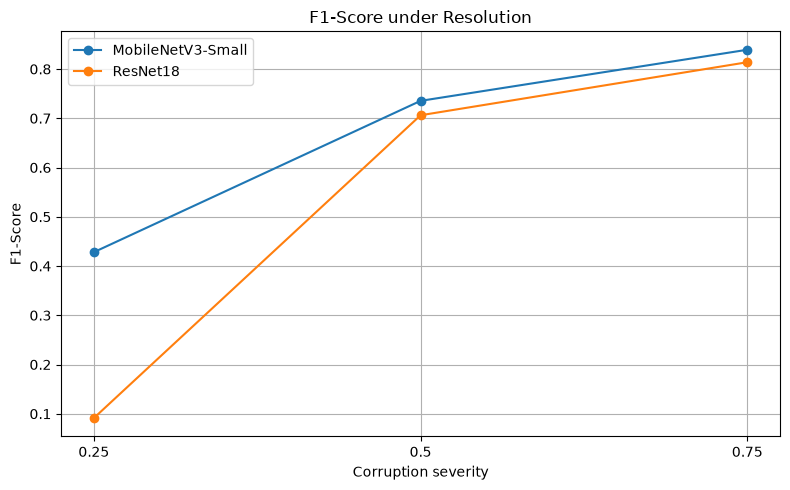

Robustness graphs saved.


In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
csv_path = os.path.join(RESULTS_DIR, "robustness_results.csv")

robustness_df = pd.read_csv(csv_path)

required = {"Model", "Corruption", "Severity", "Accuracy", "F1-Score"}
missing = required - set(robustness_df.columns)

if missing:
    print("Missing columns:", missing)
else:
    robustness_df = robustness_df.sort_values(
        ["Corruption", "Model", "Severity"]
    )

    display(robustness_df)

    for metric in ["Accuracy", "F1-Score"]:
        for corruption in robustness_df["Corruption"].unique():
            subset = robustness_df[
                robustness_df["Corruption"] == corruption
            ]

            plt.figure(figsize=(8, 5))

            for model_name in subset["Model"].unique():
                model_data = subset[
                    subset["Model"] == model_name
                ].sort_values("Severity")

                plt.plot(
                    model_data["Severity"].astype(str),
                    model_data[metric],
                    marker="o",
                    label=model_name
                )

            plt.xlabel("Corruption severity")
            plt.ylabel(metric)
            plt.title(f"{metric} under {corruption}")
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            safe_name = corruption.replace(" ", "_")
            filename = f"{metric}_{safe_name}.png"

            plt.savefig(
                os.path.join(RESULTS_DIR, filename),
                dpi=300
            )
            plt.show()

    print("Robustness graphs saved.")

In [28]:
clean_path = os.path.join(
    RESULTS_DIR, "final_model_results.csv"
)

clean_df = pd.read_csv(clean_path)

if "Unnamed: 0" in clean_df.columns:
    clean_df = clean_df.rename(
        columns={"Unnamed: 0": "Model"}
    )

display(clean_df.round(4))

clean_df.to_csv(
    os.path.join(RESULTS_DIR, "final_model_results_formatted.csv"),
    index=False
)

print("Clean comparison table saved.")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MobileNetV3-Small,0.8313,0.8045,0.8753,0.8384,0.9173
1,ResNet18,0.8387,0.8307,0.8507,0.8406,0.9198


Clean comparison table saved.


In [29]:
for filename in [
    "Grad-CAM_comparison.png",
    "MobileNet_GradCAM.png",
    "ResNet18_GradCAM.png",
    "explanation_consistency.csv"
]:
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(path):
        print("FOUND:", filename)
    else:
        print("NOT FOUND:", filename)

NOT FOUND: Grad-CAM_comparison.png
NOT FOUND: MobileNet_GradCAM.png
NOT FOUND: ResNet18_GradCAM.png
FOUND: explanation_consistency.csv


In [30]:
import os
import shutil
import zipfile

PROJECT_DIR = "/home/student/deepfake_env"
RESULTS_DIR = os.path.join(PROJECT_DIR, "deepfake_results")
BACKUP_DIR = os.path.join(PROJECT_DIR, "deepfake_project_backup")

os.makedirs(BACKUP_DIR, exist_ok=True)

# Copy all results and figures
if os.path.isdir(RESULTS_DIR):
    shutil.copytree(
        RESULTS_DIR,
        os.path.join(BACKUP_DIR, "deepfake_results"),
        dirs_exist_ok=True
    )

# Copy trained checkpoints
for filename in [
    "MobileNetV3_Small_best.pth",
    "MobileNetV3_Small_FT_best.pth",
    "ResNet18_best.pth",
    "ResNet18_FT_best.pth"
]:
    src = os.path.join(PROJECT_DIR, filename)

    if os.path.exists(src):
        shutil.copy2(src, BACKUP_DIR)
        print("Backed up:", filename)

zip_path = os.path.join(
    PROJECT_DIR, "deepfake_project_backup.zip"
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, dirs, files in os.walk(BACKUP_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            archive.write(
                full_path,
                os.path.relpath(full_path, PROJECT_DIR)
            )

print("\nBackup ZIP created:", zip_path)

Backed up: MobileNetV3_Small_best.pth
Backed up: MobileNetV3_Small_FT_best.pth
Backed up: ResNet18_best.pth
Backed up: ResNet18_FT_best.pth

Backup ZIP created: /home/student/deepfake_env/deepfake_project_backup.zip


In [31]:
import os

PROJECT_DIR = "/home/student/deepfake_env"
RESULTS_DIR = os.path.join(PROJECT_DIR, "deepfake_results")

print("===== GRAD-CAM FILES =====")

for root, dirs, files in os.walk(PROJECT_DIR):
    # Avoid searching large dependency folders
    dirs[:] = [
        d for d in dirs
        if d not in {"lib", "include", "__pycache__"}
    ]

    for filename in files:
        lower = filename.lower()

        if "gradcam" in lower or "grad-cam" in lower:
            print(os.path.join(root, filename))

print("\n===== EXPLANATION CONSISTENCY =====")

csv_path = os.path.join(
    RESULTS_DIR, "explanation_consistency.csv"
)

if os.path.exists(csv_path):
    import pandas as pd
    df = pd.read_csv(csv_path)
    print("Rows:", len(df))
    display(df)
else:
    print("CSV not found in results folder.")

===== GRAD-CAM FILES =====
/home/student/deepfake_env/deepfake_results/GradCAM_comparison.png
/home/student/deepfake_env/deepfake_project_backup/deepfake_results/GradCAM_comparison.png

===== EXPLANATION CONSISTENCY =====
Rows: 40


,Model,Image_Index,JPEG_Quality,Clean_P_Fake,Clean_Prediction,Heatmap_Cosine_Similarity
0,MobileNetV3-Small,256,50,0.773457,1,0.965566
1,MobileNetV3-Small,266,50,0.307894,0,0.915544
2,MobileNetV3-Small,281,50,0.984840,1,0.978217
3,MobileNetV3-Small,384,50,0.886993,1,0.728745
4,MobileNetV3-Small,602,50,0.893711,1,0.995672
5,MobileNetV3-Small,1292,50,0.801049,1,0.951473
6,MobileNetV3-Small,1309,50,0.912165,1,0.983199
7,MobileNetV3-Small,1351,50,0.125074,0,0.955886
8,MobileNetV3-Small,1538,50,0.718547,1,0.914255
9,MobileNetV3-Small,1574,50,0.151260,0,0.953319


In [32]:
import os
import pandas as pd

path = os.path.join(
    "/home/student/deepfake_env/deepfake_results",
    "robustness_results.csv"
)

if os.path.exists(path):
    df = pd.read_csv(path)

    print("Total rows:", len(df))
    print("\nRows per corruption and model:")

    display(
        df.groupby(
            ["Corruption", "Model"]
        ).size().unstack(fill_value=0)
    )
else:
    print("Robustness CSV not found.")

Total rows: 38

Rows per corruption and model:


Model,MobileNetV3-Small,ResNet18
Corruption,,
Brightness,4,4
Gaussian Blur,4,4
Gaussian Noise,4,4
JPEG,4,4
Resolution,3,3


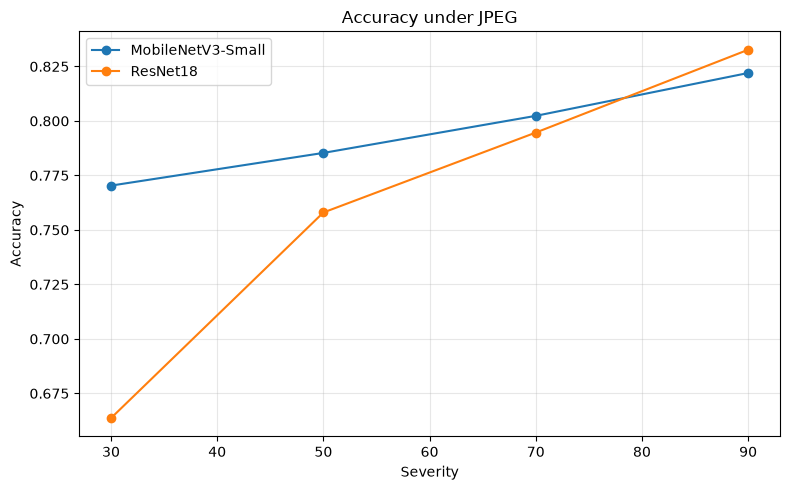

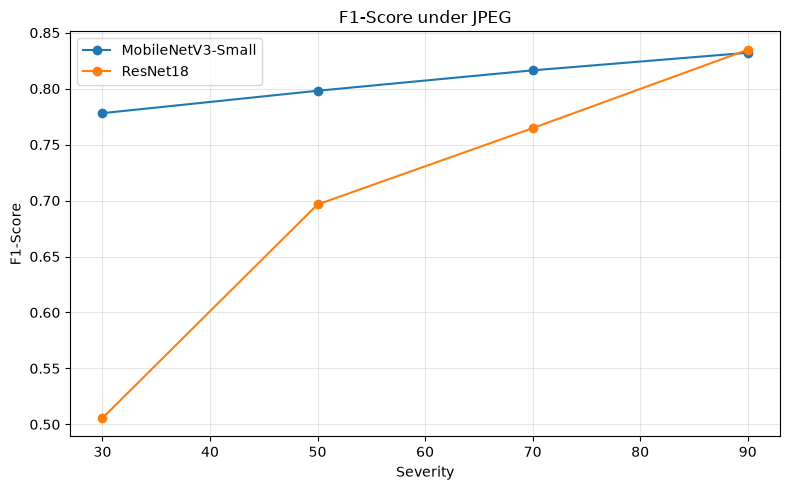

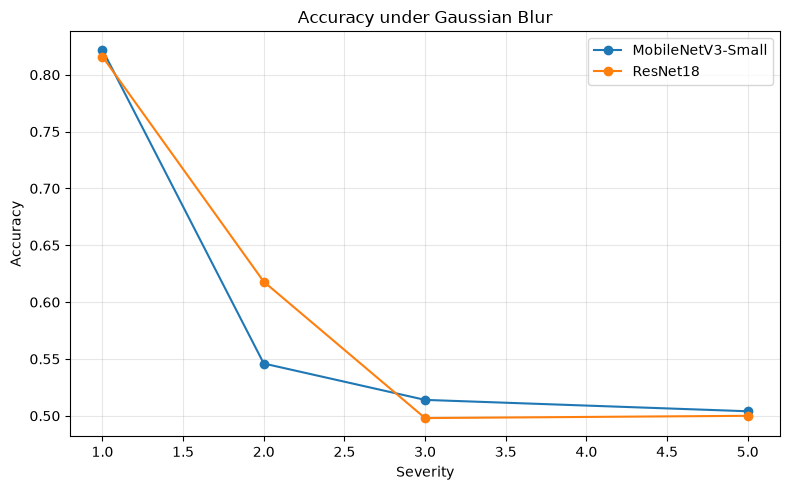

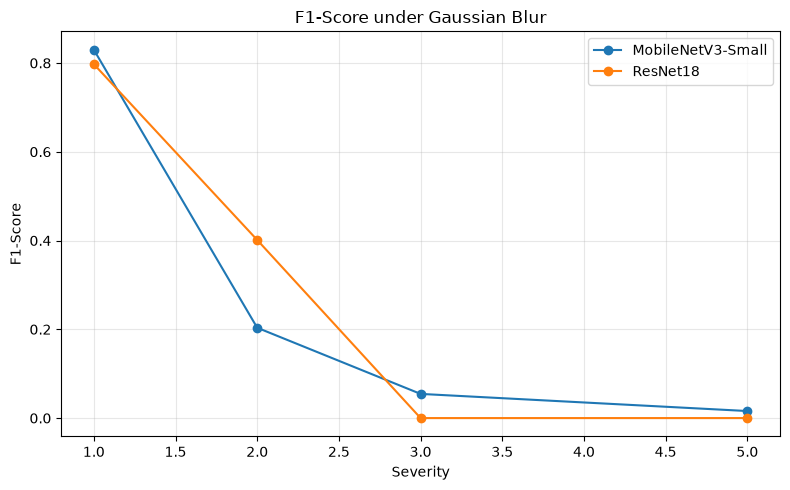

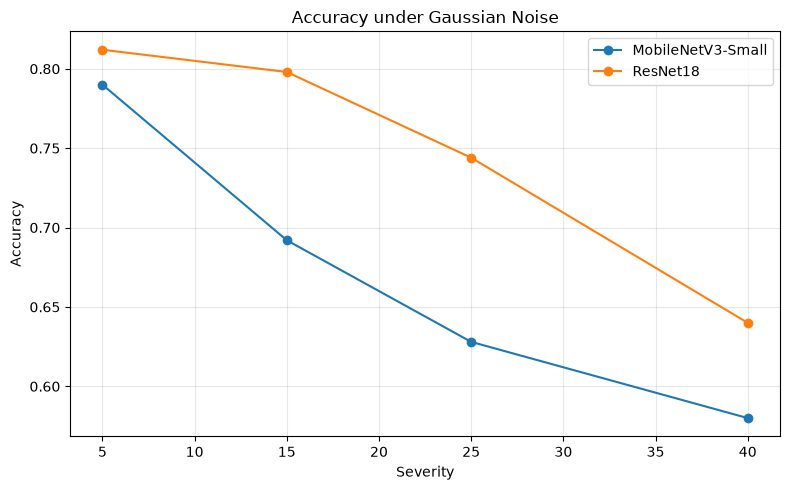

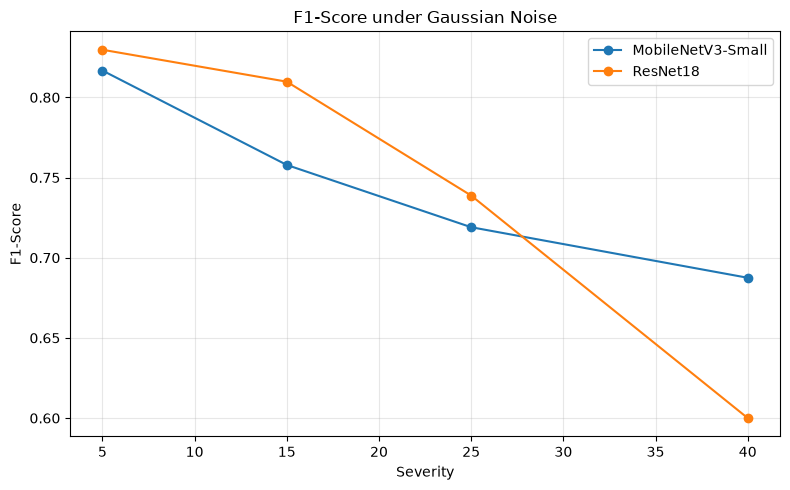

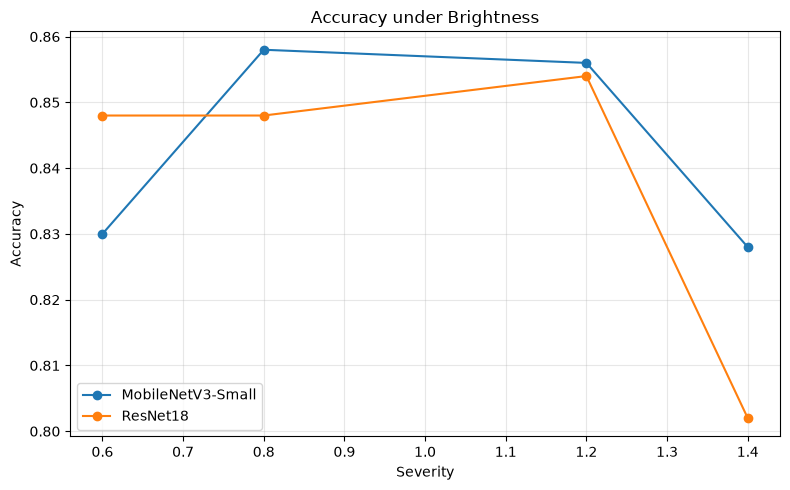

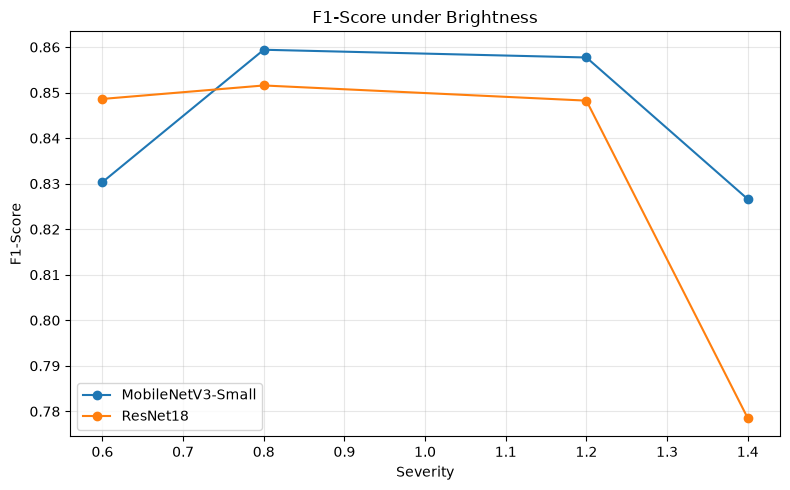

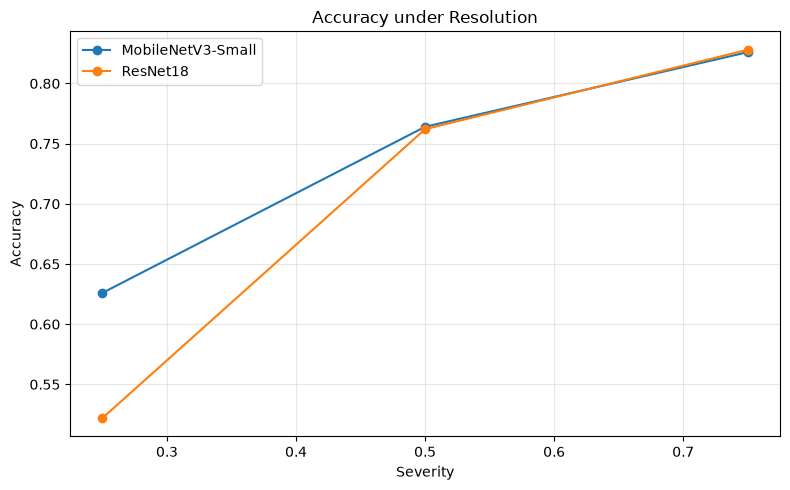

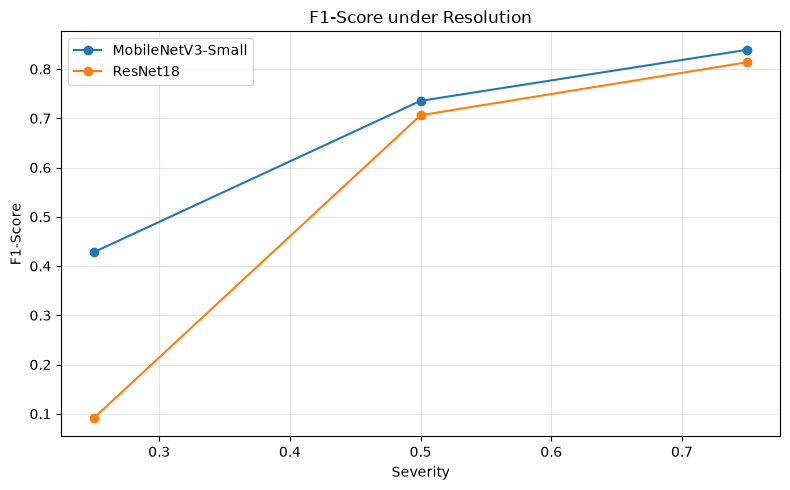

All robustness graphs saved successfully.
Robustness rows: 38
Corruption types: <StringArray>
['JPEG', 'Gaussian Blur', 'Gaussian Noise', 'Brightness', 'Resolution']
Length: 5, dtype: str


In [33]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"

csv_path = os.path.join(RESULTS_DIR, "robustness_results.csv")
df = pd.read_csv(csv_path)

# Ensure severity values are sortable
df["Severity"] = pd.to_numeric(df["Severity"])

for corruption in df["Corruption"].unique():

    subset = df[df["Corruption"] == corruption]

    for metric in ["Accuracy", "F1-Score"]:

        plt.figure(figsize=(8, 5))

        for model_name in subset["Model"].unique():

            model_df = (
                subset[subset["Model"] == model_name]
                .sort_values("Severity")
            )

            plt.plot(
                model_df["Severity"],
                model_df[metric],
                marker="o",
                label=model_name
            )

        plt.xlabel("Severity")
        plt.ylabel(metric)
        plt.title(f"{metric} under {corruption}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        filename = (
            f"{corruption.replace(' ', '_')}_{metric}.png"
        )

        plt.savefig(
            os.path.join(RESULTS_DIR, filename),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("All robustness graphs saved successfully.")
print("Robustness rows:", len(df))
print("Corruption types:", df["Corruption"].unique())

In [34]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"

robustness = pd.read_csv(
    os.path.join(RESULTS_DIR, "robustness_results.csv")
)

clean = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_model_results.csv")
)

consistency = pd.read_csv(
    os.path.join(RESULTS_DIR, "explanation_consistency.csv")
)

print("=" * 65)
print("1. CLEAN TEST PERFORMANCE")
print("=" * 65)
display(clean)

print("\n" + "=" * 65)
print("2. ROBUSTNESS RESULTS — ALL CONDITIONS")
print("=" * 65)

display(
    robustness[
        ["Model", "Corruption", "Severity", "Accuracy", "F1-Score"]
    ].sort_values(["Corruption", "Severity", "Model"])
)

print("\n" + "=" * 65)
print("3. ROBUSTNESS SUMMARY — WORST CONDITION PER MODEL")
print("=" * 65)

summary = (
    robustness.groupby(["Model", "Corruption"])
    .agg(
        Conditions=("Accuracy", "count"),
        Min_Accuracy=("Accuracy", "min"),
        Max_Accuracy=("Accuracy", "max"),
        Min_F1=("F1-Score", "min"),
        Max_F1=("F1-Score", "max")
    )
    .round(4)
)

display(summary)

print("\n" + "=" * 65)
print("4. EXPLANATION-CONSISTENCY DATA")
print("=" * 65)

print("Rows:", len(consistency))
print("Columns:", consistency.columns.tolist())

similarity_cols = [
    c for c in consistency.columns
    if "cosine" in c.lower() or "similarity" in c.lower()
]

if similarity_cols:
    display(
        consistency.groupby("Model")[similarity_cols]
        .agg(["mean", "std", "min", "max"])
        .round(4)
    )
else:
    print("No clearly named similarity column found; inspect the columns above.")

print("\nValidation complete.")

1. CLEAN TEST PERFORMANCE


,Unnamed: 0,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MobileNetV3-Small,0.831333,0.804534,0.875333,0.838442,0.917299
1,ResNet18,0.838667,0.830729,0.850667,0.840580,0.919845



2. ROBUSTNESS RESULTS — ALL CONDITIONS


,Model,Corruption,Severity,Accuracy,F1-Score
24,MobileNetV3-Small,Brightness,0.60,0.830000,0.830339
25,ResNet18,Brightness,0.60,0.848000,0.848606
26,MobileNetV3-Small,Brightness,0.80,0.858000,0.859406
27,ResNet18,Brightness,0.80,0.848000,0.851562
28,MobileNetV3-Small,Brightness,1.20,0.856000,0.857708
29,ResNet18,Brightness,1.20,0.854000,0.848233
30,MobileNetV3-Small,Brightness,1.40,0.828000,0.826613
31,ResNet18,Brightness,1.40,0.802000,0.778523
8,MobileNetV3-Small,Gaussian Blur,1.00,0.822000,0.829828
9,ResNet18,Gaussian Blur,1.00,0.816000,0.797357



3. ROBUSTNESS SUMMARY — WORST CONDITION PER MODEL


Conditions  Min_Accuracy  Max_Accuracy  \
Model             Corruption                                               
MobileNetV3-Small Brightness               4        0.8280        0.8580   
                  Gaussian Blur            4        0.5040        0.8220   
                  Gaussian Noise           4        0.5800        0.7900   
                  JPEG                     4        0.7703        0.8220   
                  Resolution               3        0.6260        0.8260   
ResNet18          Brightness               4        0.8020        0.8540   
                  Gaussian Blur            4        0.4980        0.8160   
                  Gaussian Noise           4        0.6400        0.8120   
                  JPEG                     4        0.6637        0.8327   
                  Resolution               3        0.5220        0.8280   

                                  Min_F1  Max_F1  
Model             Corruption                      
MobileNetV3-Small Brightness      0.8266  0.8594  
                  Gaussian Blur   0.0159  0.8298  
                  Gaussian Noise  0.6875  0.8168  
                  JPEG            0.7781  0.8321  
                  Resolution      0.4281  0.8392  
ResNet18          Brightness      0.7785  0.8516  
                  Gaussian Blur   0.0000  0.7974  
                  Gaussian Noise  0.6000  0.8297  
                  JPEG            0.5056  0.8348  
                  Resolution      0.0913  0.8139


4. EXPLANATION-CONSISTENCY DATA
Rows: 40
Columns: ['Model', 'Image_Index', 'JPEG_Quality', 'Clean_P_Fake', 'Clean_Prediction', 'Heatmap_Cosine_Similarity']


Heatmap_Cosine_Similarity                        
                                       mean     std     min     max
Model                                                              
MobileNetV3-Small                    0.9302  0.0581  0.7287  0.9957
ResNet18                             0.9017  0.1499  0.4728  0.9903


Validation complete.


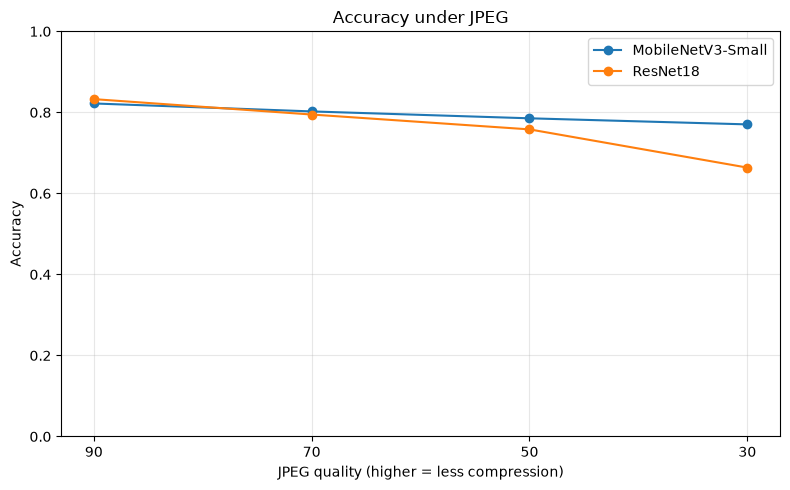

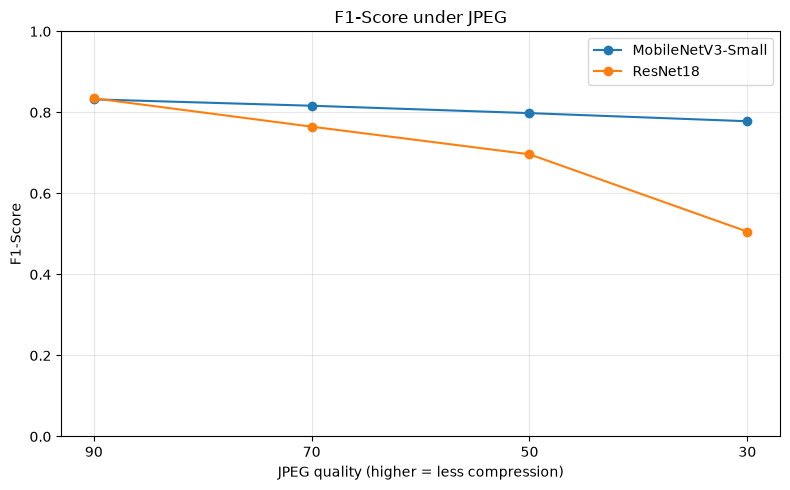

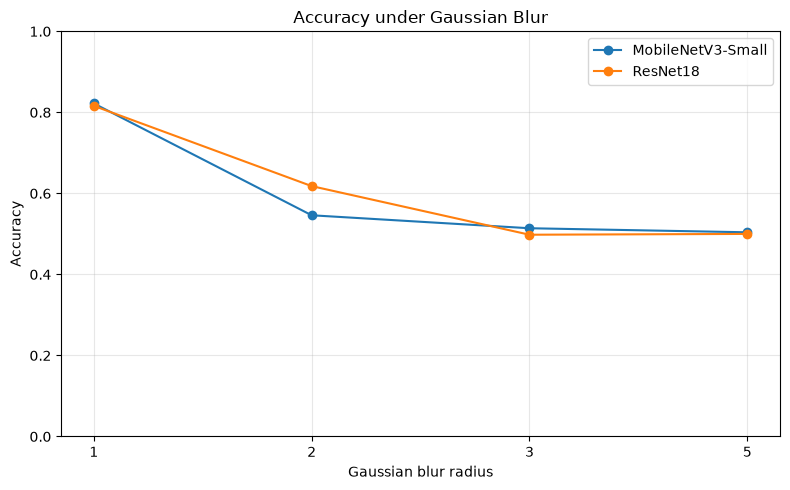

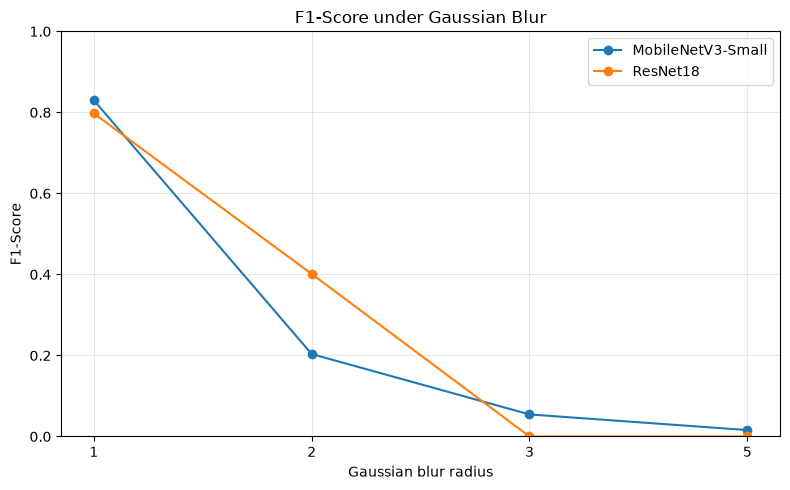

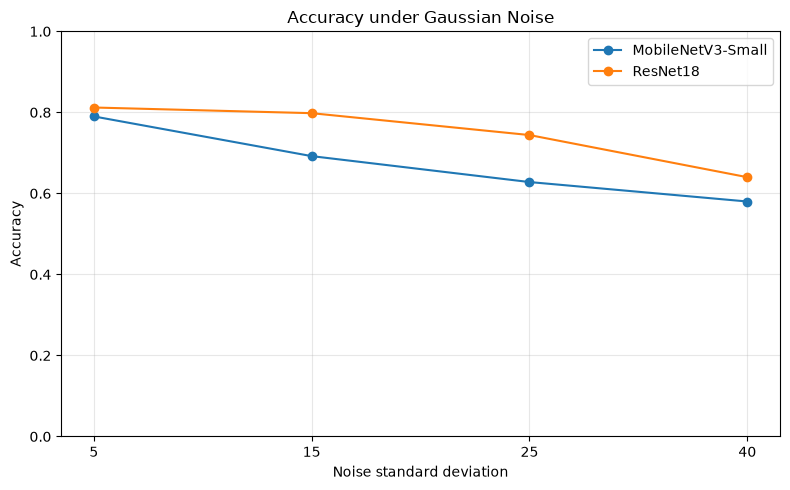

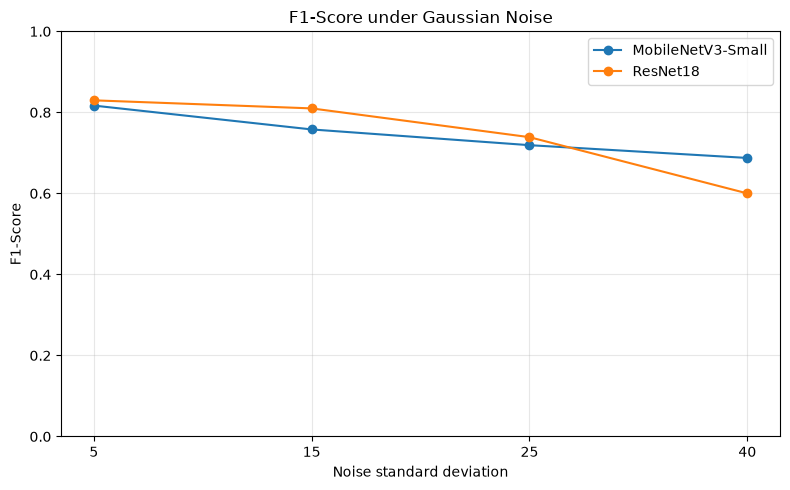

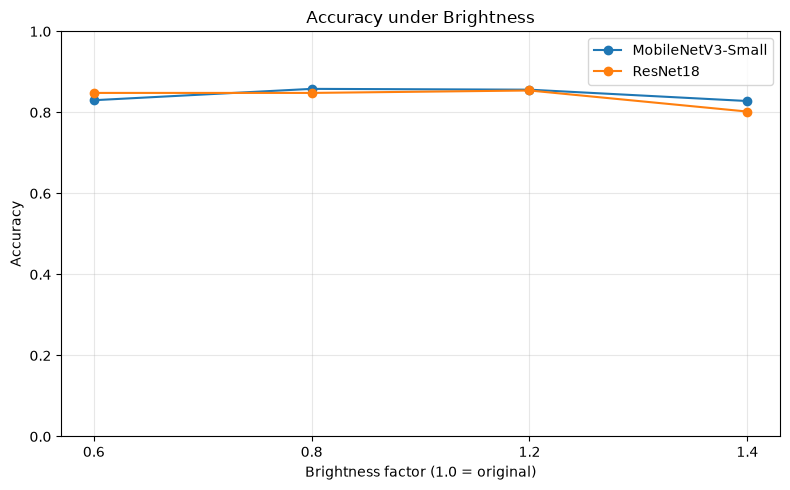

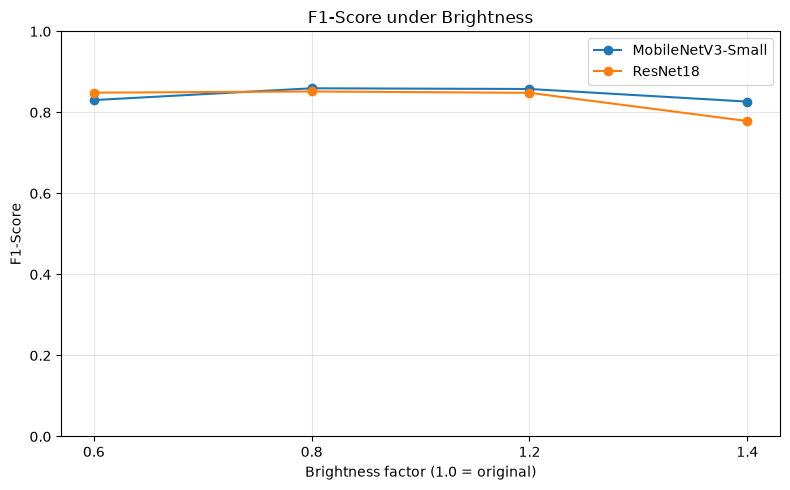

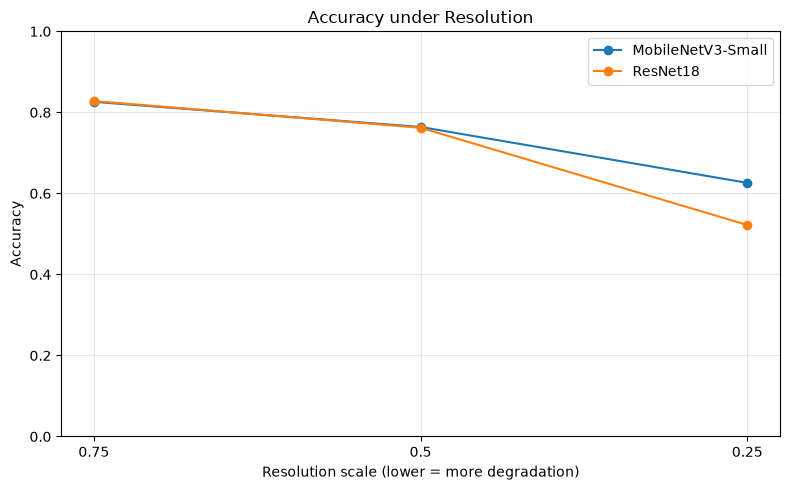

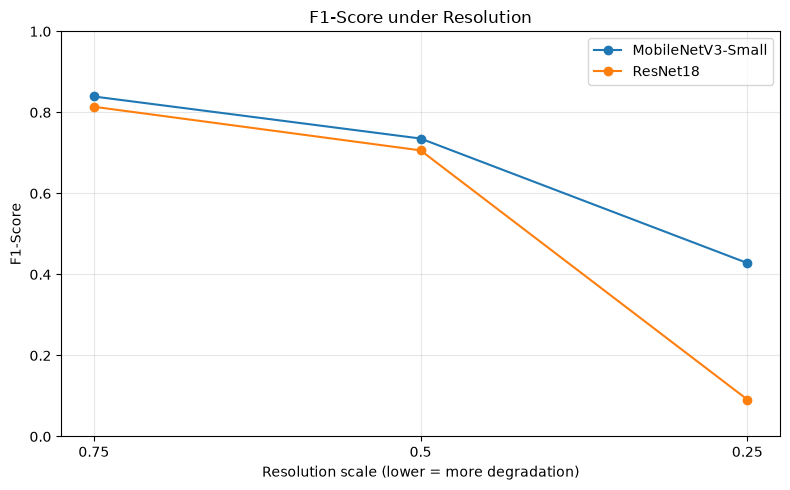

All 10 corrected graphs saved.


In [35]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"
df = pd.read_csv(
    os.path.join(RESULTS_DIR, "robustness_results.csv")
)

# Sort each corruption from least to most degraded
orders = {
    "JPEG": [90, 70, 50, 30],
    "Gaussian Blur": [1, 2, 3, 5],
    "Gaussian Noise": [5, 15, 25, 40],
    "Brightness": [0.6, 0.8, 1.2, 1.4],
    "Resolution": [0.75, 0.50, 0.25],
}

x_labels = {
    "JPEG": "JPEG quality (higher = less compression)",
    "Gaussian Blur": "Gaussian blur radius",
    "Gaussian Noise": "Noise standard deviation",
    "Brightness": "Brightness factor (1.0 = original)",
    "Resolution": "Resolution scale (lower = more degradation)",
}

for corruption, order in orders.items():
    subset = df[df["Corruption"] == corruption].copy()

    for metric in ["Accuracy", "F1-Score"]:
        plt.figure(figsize=(8, 5))

        for model_name in ["MobileNetV3-Small", "ResNet18"]:
            model_df = subset[subset["Model"] == model_name]
            model_df = model_df.set_index("Severity").reindex(order)

            plt.plot(
                range(len(order)),
                model_df[metric].values,
                marker="o",
                label=model_name
            )

        plt.xticks(range(len(order)), [str(x) for x in order])
        plt.ylim(0, 1)
        plt.xlabel(x_labels[corruption])
        plt.ylabel(metric)
        plt.title(f"{metric} under {corruption}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        filename = (
            f"{corruption.replace(' ', '_')}_{metric}_corrected.png"
        )
        plt.savefig(
            os.path.join(RESULTS_DIR, filename),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("All 10 corrected graphs saved.")

In [36]:
Device: cpu
Dataset: /home/student/Downloads/rvf10k
Class mapping: {'fake': 0, 'real': 1}
Training-source images: 7000
Training images: 5950
Validation images: 1050
Trainable parameters: 1,236,513 / 1,518,881
Loaded existing fine-tuned checkpoint.

Epoch 1/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 1/10 | Train loss 0.3257, acc 0.8629 | Val loss 0.3249, acc 0.8600 | Time 2.2 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 2/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 2/10 | Train loss 0.3219, acc 0.8588 | Val loss 0.3130, acc 0.8648 | Time 1.0 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 3/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 3/10 | Train loss 0.3094, acc 0.8728 | Val loss 0.3056, acc 0.8743 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 4/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 4/10 | Train loss 0.3106, acc 0.8696 | Val loss 0.3036, acc 0.8695 | Time 1.1 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 5/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 5/10 | Train loss 0.3058, acc 0.8676 | Val loss 0.2985, acc 0.8819 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 6/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 6/10 | Train loss 0.3004, acc 0.8745 | Val loss 0.2948, acc 0.8810 | Time 1.0 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 7/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 7/10 | Train loss 0.2940, acc 0.8773 | Val loss 0.2876, acc 0.8790 | Time 1.1 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 8/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 8/10 | Train loss 0.2932, acc 0.8741 | Val loss 0.2863, acc 0.8857 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Epoch 9/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 9/10 | Train loss 0.2828, acc 0.8803 | Val loss 0.2882, acc 0.8810 | Time 1.1 min
No validation-loss improvement.

Epoch 10/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 10/10 | Train loss 0.2725, acc 0.8909 | Val loss 0.2786, acc 0.8886 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Training complete.
Best validation loss: 0.27858
Checkpoint: /home/student/deepfake_env/MobileNetV3_Small_extended_best.pth
History: /home/student/deepfake_env/MobileNetV3_Small_extended_history.csv
import os
import pandas as pd

RESULTS_DIR = "/home/student/deepfake_env/deepfake_results"

robustness = pd.read_csv(
    os.path.join(RESULTS_DIR, "robustness_results.csv")
)

consistency = pd.read_csv(
    os.path.join(RESULTS_DIR, "explanation_consistency.csv")
)

# Correctly formatted robustness summary
robust_summary = (
    robustness.groupby(["Model", "Corruption"])
    .agg(
        Number_of_Conditions=("Accuracy", "count"),
        Min_Accuracy=("Accuracy", "min"),
        Max_Accuracy=("Accuracy", "max"),
        Min_F1=("F1-Score", "min"),
        Max_F1=("F1-Score", "max")
    )
    .reset_index()
    .round(4)
)

robust_summary.to_csv(
    os.path.join(RESULTS_DIR, "robustness_summary.csv"),
    index=False
)

# Explanation consistency summary
consistency_summary = (
    consistency.groupby("Model")["Heatmap_Cosine_Similarity"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
    .round(4)
)

consistency_summary.to_csv(
    os.path.join(RESULTS_DIR, "explanation_consistency_summary.csv"),
    index=False
)

display(robust_summary)
display(consistency_summary)

print("Saved:")
print("robustness_summary.csv")
print("explanation_consistency_summary.csv")

,Model,Corruption,Number_of_Conditions,Min_Accuracy,Max_Accuracy,Min_F1,Max_F1
0,MobileNetV3-Small,Brightness,4,0.8280,0.8580,0.8266,0.8594
1,MobileNetV3-Small,Gaussian Blur,4,0.5040,0.8220,0.0159,0.8298
2,MobileNetV3-Small,Gaussian Noise,4,0.5800,0.7900,0.6875,0.8168
3,MobileNetV3-Small,JPEG,4,0.7703,0.8220,0.7781,0.8321
4,MobileNetV3-Small,Resolution,3,0.6260,0.8260,0.4281,0.8392
5,ResNet18,Brightness,4,0.8020,0.8540,0.7785,0.8516
6,ResNet18,Gaussian Blur,4,0.4980,0.8160,0.0000,0.7974
7,ResNet18,Gaussian Noise,4,0.6400,0.8120,0.6000,0.8297
8,ResNet18,JPEG,4,0.6637,0.8327,0.5056,0.8348
9,ResNet18,Resolution,3,0.5220,0.8280,0.0913,0.8139


,Model,count,mean,std,min,max
0,MobileNetV3-Small,20,0.9302,0.0581,0.7287,0.9957
1,ResNet18,20,0.9017,0.1499,0.4728,0.9903


Saved:
robustness_summary.csv
explanation_consistency_summary.csv


In [1]:

import copy
import csv
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
ROOT = Path.home() / "deepfake_env"
DATASET_PATH = Path.home() / "Downloads" / "rvf10k"
CHECKPOINT = ROOT / "MobileNetV3_Small_FT_best.pth"
OUTPUT = ROOT / "MobileNetV3_Small_extended_best.pth"
HISTORY = ROOT / "MobileNetV3_Small_extended_history.csv"

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 10
PATIENCE = 3
LR = 1e-5

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cpu")
torch.set_num_threads(4)

assert CHECKPOINT.exists(), f"Missing checkpoint: {CHECKPOINT}"
assert (DATASET_PATH / "train").exists(), "Training dataset missing"

print("Device:", device)
print("Dataset:", DATASET_PATH)

# --------------------------------------------------
# 2. Image preprocessing
# --------------------------------------------------
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Separate dataset objects ensure validation is not randomly augmented.
train_base = datasets.ImageFolder(
    str(DATASET_PATH / "train"),
    transform=train_transform
)
val_base = datasets.ImageFolder(
    str(DATASET_PATH / "train"),
    transform=eval_transform
)

assert train_base.class_to_idx == val_base.class_to_idx
print("Class mapping:", train_base.class_to_idx)
print("Training-source images:", len(train_base))

# Project convention: real=0, fake=1
class FakePositiveDataset(Dataset):
    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, original_label = self.base[idx]
        return image, 1 - original_label

labels = np.array([
    1 - label for label in train_base.targets
])
indices = np.arange(len(train_base))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

train_dataset = Subset(
    FakePositiveDataset(train_base), train_idx
)
val_dataset = Subset(
    FakePositiveDataset(val_base), val_idx
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# --------------------------------------------------
# 3. Restore the existing fine-tuned checkpoint
# --------------------------------------------------
model = models.mobilenet_v3_small(weights=None)
model.classifier[-1] = nn.Linear(
    model.classifier[-1].in_features, 1
)

state = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=True
)
model.load_state_dict(state)

# Train the final three feature blocks and classifier.
for p in model.parameters():
    p.requires_grad = False

for p in model.features[-3:].parameters():
    p.requires_grad = True

for p in model.classifier.parameters():
    p.requires_grad = True

model = model.to(device)

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable:,} / {total_params:,}")
print("Loaded existing fine-tuned checkpoint.")

# --------------------------------------------------
# 4. Optimizer, loss, and scheduler
# --------------------------------------------------
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0
history = []

# --------------------------------------------------
# 5. Extended fine-tuning
# --------------------------------------------------
for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()

    # Training
    model.train()

    # Keep frozen feature blocks and their BatchNorm
    # statistics fixed.
    model.features[:-3].eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels_batch in tqdm(
        train_loader, desc=f"Epoch {epoch}/{MAX_EPOCHS}"
    ):
        images = images.to(device)
        labels_batch = labels_batch.float().to(device).unsqueeze(1)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels_batch)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            (torch.sigmoid(logits) >= 0.5) == labels_batch.bool()
        ).sum().item()
        train_total += images.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation: no gradients or random augmentation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.float().to(device).unsqueeze(1)

            logits = model(images)
            loss = criterion(logits, labels_batch)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                (torch.sigmoid(logits) >= 0.5) == labels_batch.bool()
            ).sum().item()
            val_total += images.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total
    scheduler.step(val_loss)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"]
    }
    history.append(row)

    print(
        f"\nEpoch {epoch}/{MAX_EPOCHS} | "
        f"Train loss {train_loss:.4f}, acc {train_acc:.4f} | "
        f"Val loss {val_loss:.4f}, acc {val_acc:.4f} | "
        f"Time {(time.time()-start)/60:.1f} min"
    )

    # Select the checkpoint using validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, OUTPUT)
        epochs_without_improvement = 0
        print("Saved new best checkpoint:", OUTPUT.name)
    else:
        epochs_without_improvement += 1
        print("No validation-loss improvement.")

    # Save progress after every epoch.
    with open(HISTORY, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

# Restore best validation checkpoint in memory.
model.load_state_dict(best_state)
model.eval()

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 5))
print("Checkpoint:", OUTPUT)
print("History:", HISTORY)


Device: cpu
Dataset: /home/student/Downloads/rvf10k
Class mapping: {'fake': 0, 'real': 1}
Training-source images: 7000
Training images: 5950
Validation images: 1050
Trainable parameters: 1,236,513 / 1,518,881
Loaded existing fine-tuned checkpoint.


Epoch 1/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 1/10 | Train loss 0.3257, acc 0.8629 | Val loss 0.3249, acc 0.8600 | Time 2.2 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth


Epoch 2/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 2/10 | Train loss 0.3219, acc 0.8588 | Val loss 0.3130, acc 0.8648 | Time 1.0 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth


Epoch 3/10:   0%|          | 0/186 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 9/10 | Train loss 0.2828, acc 0.8803 | Val loss 0.2882, acc 0.8810 | Time 1.1 min
No validation-loss improvement.


Epoch 10/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 10/10 | Train loss 0.2725, acc 0.8909 | Val loss 0.2786, acc 0.8886 | Time 0.9 min
Saved new best checkpoint: MobileNetV3_Small_extended_best.pth

Training complete.
Best validation loss: 0.27858
Checkpoint: /home/student/deepfake_env/MobileNetV3_Small_extended_best.pth
History: /home/student/deepfake_env/MobileNetV3_Small_extended_history.csv


In [2]:

from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

ROOT = Path.home() / "deepfake_env"
DATASET_PATH = Path.home() / "Downloads" / "rvf10k"
CHECKPOINT = ROOT / "MobileNetV3_Small_extended_best.pth"

device = torch.device("cpu")
torch.set_num_threads(4)

class FakePositiveDataset(Dataset):
    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, original_label = self.base[idx]
        return image, 1 - original_label  # real=0, fake=1

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_base = datasets.ImageFolder(
    str(DATASET_PATH / "valid"),
    transform=transform
)
test_dataset = FakePositiveDataset(test_base)
test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=0
)

model = models.mobilenet_v3_small(weights=None)
model.classifier[-1] = nn.Linear(
    model.classifier[-1].in_features, 1
)
state = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=True
)
model.load_state_dict(state)
model.to(device)
model.eval()

all_labels, all_probs = [], []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images)
        probs = torch.sigmoid(logits).squeeze(1)

        all_labels.extend(labels.numpy().tolist())
        all_probs.extend(probs.numpy().tolist())

y_true = np.asarray(all_labels)
y_prob = np.asarray(all_probs)
y_pred = (y_prob >= 0.5).astype(int)

print("Held-out images:", len(y_true))
print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))
print("\nConfusion matrix [real=0, fake=1]:")
print(confusion_matrix(y_true, y_pred))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Real", "Fake"],
    zero_division=0
))


Held-out images: 3000
Accuracy : 0.8563
Precision: 0.8407
Recall   : 0.8793
F1-score : 0.8596
ROC-AUC  : 0.9355

Confusion matrix [real=0, fake=1]:
[[1250  250]
 [ 181 1319]]

Classification report:
              precision    recall  f1-score   support

        Real       0.87      0.83      0.85      1500
        Fake       0.84      0.88      0.86      1500

    accuracy                           0.86      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.86      0.86      0.86      3000



In [4]:

import copy
import csv
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

ROOT = Path.home() / "deepfake_env"
DATASET_PATH = Path.home() / "Downloads" / "rvf10k"

CHECKPOINT = ROOT / "ResNet18_FT_best.pth"
OUTPUT = ROOT / "ResNet18_extended_best.pth"
HISTORY = ROOT / "ResNet18_extended_history.csv"

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 10
PATIENCE = 3
LR = 1e-5

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(4)
device = torch.device("cpu")

assert CHECKPOINT.exists(), f"Checkpoint missing: {CHECKPOINT}"
assert (DATASET_PATH / "train").exists(), "Training dataset missing"

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2, contrast=0.2, saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_base = datasets.ImageFolder(
    str(DATASET_PATH / "train"), transform=train_transform
)
val_base = datasets.ImageFolder(
    str(DATASET_PATH / "train"), transform=eval_transform
)

assert train_base.class_to_idx == val_base.class_to_idx
labels = np.array([1 - label for label in train_base.targets])
indices = np.arange(len(train_base))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

class FakePositiveDataset(Dataset):
    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, original_label = self.base[idx]
        return image, 1 - original_label

train_dataset = Subset(FakePositiveDataset(train_base), train_idx)
val_dataset = Subset(FakePositiveDataset(val_base), val_idx)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

# Restore ResNet18 fine-tuned weights
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)
state = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=True
)
model.load_state_dict(state)

# Fine-tune layer4 and the final classifier
for p in model.parameters():
    p.requires_grad = False

for p in model.layer4.parameters():
    p.requires_grad = True

for p in model.fc.parameters():
    p.requires_grad = True

model = model.to(device)

print("Loaded:", CHECKPOINT.name)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=1
)

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
no_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()
    model.train()

    # Keep frozen backbone layers and BatchNorm statistics fixed
    for module in [model.conv1, model.bn1, model.layer1,
                   model.layer2, model.layer3]:
        module.eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, y in tqdm(
        train_loader, desc=f"Epoch {epoch}/{MAX_EPOCHS}"
    ):
        images = images.to(device)
        y = y.float().to(device).unsqueeze(1)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            (torch.sigmoid(logits) >= 0.5) == y.bool()
        ).sum().item()
        train_total += images.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, y in val_loader:
            images = images.to(device)
            y = y.float().to(device).unsqueeze(1)

            logits = model(images)
            loss = criterion(logits, y)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                (torch.sigmoid(logits) >= 0.5) == y.bool()
            ).sum().item()
            val_total += images.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total
    scheduler.step(val_loss)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"]
    }
    history.append(row)

    print(
        f"\nEpoch {epoch}: "
        f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.4f} | "
        f"time={(time.time()-start)/60:.1f} min"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, OUTPUT)
        no_improvement = 0
        print("Saved best checkpoint:", OUTPUT.name)
    else:
        no_improvement += 1
        print("No validation-loss improvement.")

    with open(HISTORY, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)

    if no_improvement >= PATIENCE:
        print("Early stopping.")
        break

model.load_state_dict(best_state)
model.eval()

print("\nResNet18 fine-tuning complete.")
print("Best validation loss:", round(best_val_loss, 5))
print("Checkpoint:", OUTPUT)
print("History:", HISTORY)


Loaded: ResNet18_FT_best.pth
Training images: 5950
Validation images: 1050
Trainable parameters: 8394241


Epoch 1/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 1: train loss=0.3321, acc=0.8608 | val loss=0.3312, acc=0.8562 | time=3.9 min
Saved best checkpoint: ResNet18_extended_best.pth


Epoch 2/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 2: train loss=0.2903, acc=0.8802 | val loss=0.3121, acc=0.8695 | time=4.3 min
Saved best checkpoint: ResNet18_extended_best.pth


Epoch 3/10:   0%|          | 0/186 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 9: train loss=0.1485, acc=0.9477 | val loss=0.2423, acc=0.9029 | time=3.6 min
No validation-loss improvement.


Epoch 10/10:   0%|          | 0/186 [00:00<?, ?it/s]


Epoch 10: train loss=0.1385, acc=0.9476 | val loss=0.2389, acc=0.9124 | time=3.6 min
Saved best checkpoint: ResNet18_extended_best.pth

ResNet18 fine-tuning complete.
Best validation loss: 0.23889
Checkpoint: /home/student/deepfake_env/ResNet18_extended_best.pth
History: /home/student/deepfake_env/ResNet18_extended_history.csv
